# Predicting Diabetes Risk Using NHANES Data
#### An End-to-End Data Science Project
#### Python | Scikit-Learn | Tensor Flow | Pandas | NumPy | Flask
#### Craig Reynolds

## Introduction
This project develops and deploys a machine-learning model using NHANES data to estimate the probability of diabetes or borderline diabetes from readily available features. Demographic, socioeconomic, behavioral, and physical characteristics are used while intentionally ecluding features that require laboratory testing. This allows the development of a highly accessible prediction platform that can be deployed through a simple web application.  The end goal is an accurate prediction algorithm that can be paired with a simple, user friendly interface.

The scope of this project includes data cleaning, feature engineering, custom preprocessing, grouped income imputation, a comparison between traditional machine-learning models and a neural network, probability-based model evaluation, calibration analysis, model experimentation, and deployment through Flask.

## Dataset Information
Various datasets were used from the National Health and Nutrition Examination Survey (NHANES), which combines interviews and standardized health examinations from a sample designed to be representative of the general population.

## Tools and Libraries Used
### -Python -Scikit-Learn -TensorFlow -Keras -Pandas -NumPy -Matplotlib -Seaborn  -Flask

## Datasets Used

- **DEMO_L** —  Demographics
- **BMX_L** — BMI and body measurements
- **SMQ_L** — Smoking behavior
- **ALQ_L** — Alcohol consumption
- **PAQ_L** — Physical activity
- **DIQ_L** — Diabetes status (Target Variable)

## Variables Explored

- **RIDAGEYR** — Age in years
- **RIAGENDR** — Gender
- **RIDRETH3** — Race
- **INDFMPIR** — Income / Poverty Line
- **BMXBMI** — Body Mass Index
- **SMQ020** — Ever Smoked a Total of 100 Cigarettes
- **ALQ111** — Ever Had an Alcoholic Drink
- **ALQ151** — Ever Had 4/5 drinks Per Day Every Day
- **PAD810Q/U - PAD790Q/U** — Frequency of physical activity
- **DIQ010** — Diabetes Diagnosis (Target Variable)

## Loading the NHANES Files
These datasets have been chosen because they contain demographic and behavior information that is readily available to anyone who might want to predict their risk for diabetes. Features that require laboratory testing were avoided to make the predictions accessible to a wide audience of potential users.

In [2]:
import pandas as pd
import numpy as np

#Use read_sas to load the files and assign variable names
demos = pd.read_sas('data/DEMO_L.xpt')
bmi = pd.read_sas('data/BMX_L.xpt')
smoking = pd.read_sas('data/SMQ_L.xpt')
alcohol = pd.read_sas('data/ALQ_L.xpt')
exercise = pd.read_sas('data/PAQ_L.xpt')
diabetes = pd.read_sas('data/DIQ_L.xpt')

## Exploration of the Alcohol Dataset
The first step is to explore the data and get an idea of how the data is organized, how many missing values there are and what kind of data cleaning tasks are needed. The alcohol dataset will be explored first. The other datasets will likely have similar formats and cleaning requirements.

In [7]:
#Show the shape of the dataset
print('Shape:', alcohol.shape)
print('\n')

#View the data types, missing values and percent missing for each column.
alc = pd.DataFrame({
"Dtype": alcohol.dtypes,
"Number Missing": alcohol.isna().sum(),
"PCT Missing": (alcohol.isna().mean() * 100).round(2) })
print(alc)
print('\n')

#View the dataset
alcohol.head()
print('\n')

Shape: (6337, 9)


          Dtype  Number Missing  PCT Missing
SEQN    float64               0         0.00
ALQ111  float64             856        13.51
ALQ121  float64            1415        22.33
ALQ130  float64            2268        35.79
ALQ142  float64            2255        35.58
ALQ270  float64            3971        62.66
ALQ280  float64            3975        62.73
ALQ151  float64            1436        22.66
ALQ170  float64            3979        62.79


       SEQN  ALQ111        ALQ121  ALQ130        ALQ142        ALQ270  ALQ280  \
0  130378.0     NaN           NaN     NaN           NaN           NaN     NaN   
1  130379.0     1.0  2.000000e+00     3.0  5.397605e-79           NaN     NaN   
2  130380.0     1.0  1.000000e+01     1.0  5.397605e-79           NaN     NaN   
3  130386.0     1.0  4.000000e+00     2.0  1.000000e+01  5.397605e-79    10.0   
4  130387.0     1.0  5.397605e-79     NaN           NaN           NaN     NaN   

   ALQ151        ALQ170  
0     NaN       

### Summary of the Alcohol Dataset
At first glance many of the variables appear to have a large number of missing values. However, examination of the NHANES codebook for ALQ_L reveals that skip logic was used in the surveys. Meaning, if an individual responded as never drinking alcohol in a prior question, they were not asked subsequent questions about alcohol consumption. Those skipped questions are recorded as missing values. 

Importing the NHANES XML metadata resulted in several variables being read as floating-point values, even though they represent coded integer responses. 

ALQ111 (Have you ever drank alcohol) and ALQ151 (Have you ever drank more than 4/5 drinks per day consistently) are selected as the most useful alcohol related variables. It is important to avoid features pertaining to current behavior. Historical behavior or cumulative consumption is much better because current behavior can change due to a diagnosis leading to reverse causation. 

### The Valid Response Codes Are:
- 1 = Yes
- 2 = No
- 7 = Refused
- 9 = Don't know

### Cleaning the Alcohol Dataset
Next, various data cleaning steps must be performed such as narrowing the dataframe down to columns of interest, converting data types and handling missing values.

In [15]:
#Remove columns I'm not interested in using
alcohol = alcohol[['SEQN', 'ALQ111', 'ALQ151']].copy()


#Convert values to Int64 and round to the nearest whole number
alcohol['SEQN'] = alcohol['SEQN'].astype('Int64')
alcohol['ALQ111'] = alcohol['ALQ111'].round().astype('Int64')
alcohol['ALQ151'] = alcohol['ALQ151'].round().astype('Int64')

#Set the value for ALQ151 to '2' (No), if the value for ALQ111 is '2' (No).
alcohol.loc[alcohol['ALQ111'] == 2, 'ALQ151'] = 2

#Replace 7 (Refused) and 9 (Don't Know) with missing values
alcohol['ALQ111'] = alcohol['ALQ111'].replace([7, 9], np.nan)
alcohol['ALQ151'] = alcohol['ALQ151'].replace([7, 9], np.nan)

#Display number of missing values
missalc = pd.DataFrame({
    "Missing Values": alcohol.isna().sum() })

print(missalc)
print('\n')

#Display ALQ111 Value Counts
alq111 = alcohol['ALQ111'].value_counts().reset_index() 
alq111.columns = ['ALQ111', 'Count'] 
print(alq111.to_string(index=False))
print('\n')

#Display ALQ151 Value Counts
alq151 = alcohol['ALQ151'].value_counts().reset_index() 
alq151.columns = ['ALQ151', 'Count'] 
print(alq151.to_string(index=False))
print('\n')

#View the cleaned alcohol dataset
alcohol.head(8)

        Missing Values
SEQN                 0
ALQ111             861
ALQ151             884


 ALQ111  Count
      1   4918
      2    558


 ALQ151  Count
      2   4537
      1    916


     SEQN  ALQ111  ALQ151
0  130378    <NA>    <NA>
1  130379       1       2
2  130380       1       2
3  130386       1       2
4  130387       1       2
5  130388    <NA>    <NA>
6  130389       1       2
7  130390    <NA>    <NA>


### Create an Automated Cleaning Function
A function which automates the most basic data cleaning tasks that were performed on the alcohol data is created. The function takes the data frame name, columns of interest and values which should be converted into missing values as inputs. Given these inputs, the function will drop unwanted columns and convert values appropriately.

In [43]:
def clean_nhanes(df, columns, missing_codes):
    df = df[columns].copy()

    for col in columns:
            df[col] = df[col].round().astype("Int64")
            df[col] = df[col].replace(missing_codes, np.nan)
    return df

### Cleaning The Smoking Dataset
The variable of interest in this dataset is SMQ020 (Have you smoked at least 100 cigarettes in your life?). This was chosen because it is an excellent account of the individual's smoking history and 100 cigarettes is the standard epidemiologic benchmark for someone who has been a "smoker". The cleaning function is applied to this dataset.

In [46]:
#Utilize the cleaning function to clean the smoking dataset.
smoking = clean_nhanes(
    df = smoking, 
    columns = ['SEQN', 'SMQ020'], 
    missing_codes = [7, 9] )

#Show the number of missing values.
print("Missing Values: ", smoking['SMQ020'].isna().sum())
print(f"Percent Missing: {smoking['SMQ020'].isna().mean():.2%}")
print('\n')

#show Value Counts
print( smoking['SMQ020'].value_counts())
print('\n')

#Show Dataset
smoking.head()

Missing Values:  894
Percent Missing: 9.92%


SMQ020
2    4878
1    3243
Name: count, dtype: Int64




,SEQN,SMQ020
0,130378,1
1,130379,1
2,130380,2
3,130384,2
4,130385,2


### Cleaning the BMI Dataset
Since BMI is a float value, the cleaning function will not be used here. All the BMI values are either a valid float or a valid missing value so there is no recoding needed for this feature.

In [50]:
#Remove columns that are not being used
bmi = bmi[["SEQN", "BMXBMI"]].copy()

#Convert SEQN to integers
bmi['SEQN'] = bmi['SEQN'].round().astype('Int64')

#Show number of missing values
print("Missing Values: ", bmi['BMXBMI'].isna().sum())
print(f"Percent Missing: {bmi['BMXBMI'].isna().mean():.2%}")
print('\n')

#Show Dataset
bmi.head(10)

Missing Values:  389
Percent Missing: 4.39%




,SEQN,BMXBMI
0,130378,27.0
1,130379,33.5
2,130380,29.7
3,130381,23.8
4,130382,NaN
5,130386,30.2
6,130387,42.6
7,130388,43.7
8,130389,28.0
9,130390,46.0


## Cleaning & Engineering the Exercise Dataset
Next, the exercise dataset will be explored and cleaned. Data engineering will also be performed to combine moderate and vigorous exercise into a single measure of frequency. For this project, variables describing how often an individual engages in moderate or vigorous physical activity will be selected. NHANES stores these variables as a numeric value (frequency) together with a corresponding unit indicating whether that value represents occurrences per day, week, month, or year. These two variables will be standardized together into a common time scale before being combined. The duration of each exercise session will not be used because it adds additional complexity while providing limited benefit for the objectives of this project. Sedentary time per day will also be used.  Since this dataset requires substantial unique preprocessing and feature engineering, the generalized cleaning function will not be used here.

In [54]:
from IPython.display import display

#View the dataframe
display(exercise.head(8))

#Remove columns that are not being used
exercise = exercise[['SEQN', 'PAD790Q', 'PAD790U', 'PAD810Q', 'PAD810U', 'PAD680']].copy()

#Convert floats to integers
exercise['SEQN'] = exercise['SEQN'].round().astype('Int64')
exercise['PAD790Q'] = exercise['PAD790Q'].round().astype('Int64')
exercise['PAD810Q'] = exercise['PAD810Q'].round().astype('Int64')
exercise['PAD680'] = exercise['PAD680'].round().astype('Int64')

#Convert character bytes format from the .xpt files into string format
exercise['PAD790U'] = exercise['PAD790U'].str.decode('utf-8')
exercise['PAD810U'] = exercise['PAD810U'].str.decode('utf-8')

#Check for correct transformations
display(exercise.head())

,SEQN,PAD790Q,PAD790U,PAD800,PAD810Q,PAD810U,PAD820,PAD680
0,130378.0,3.000000e+00,b'W',45.0,3.000000e+00,b'W',45.0,360.0
1,130379.0,4.000000e+00,b'W',45.0,3.000000e+00,b'W',45.0,480.0
2,130380.0,1.000000e+00,b'W',20.0,5.397605e-79,b'',NaN,240.0
3,130384.0,5.397605e-79,b'',NaN,5.397605e-79,b'',NaN,60.0
4,130385.0,1.000000e+00,b'D',90.0,1.000000e+00,b'W',60.0,180.0
5,130386.0,1.000000e+00,b'W',30.0,1.000000e+00,b'M',30.0,180.0
6,130387.0,5.397605e-79,b'',NaN,5.397605e-79,b'',NaN,1200.0
7,130388.0,5.000000e+00,b'W',180.0,5.397605e-79,b'',NaN,360.0


,SEQN,PAD790Q,PAD790U,PAD810Q,PAD810U,PAD680
0,130378,3,W,3,W,360
1,130379,4,W,3,W,480
2,130380,1,W,0,,240
3,130384,0,,0,,60
4,130385,1,D,1,W,180


In [60]:
#Convert unit columns into multipliers to express frequency per week
#D (per day) = 7, 7 days per week
#W (per week) = 1
#M (per month) = 1/4.33 = 0.231, 4.33 weeks per month
#Y (per year) = 1/52 = 0.0192, 52 weeks per year
exercise['PAD790U'] = exercise['PAD790U'].replace({'W': 1, 'D': 7, 'M': 0.231, 'Y': 0.0192})
exercise['PAD810U'] = exercise['PAD810U'].replace({'W': 1, 'D': 7, 'M': 0.231, 'Y': 0.0192})

#Replace missing empty strings with np.nan floats
exercise['PAD790U'] = exercise['PAD790U'].replace('', np.nan)
exercise['PAD810U'] = exercise['PAD810U'].replace('', np.nan)

#Convert datatypes to floats.
exercise['PAD790U'] = exercise['PAD790U'].astype(float)
exercise['PAD810U'] = exercise['PAD810U'].astype(float)

#Skip logic was used, set the multiplier to 0 if the frequency value is 0.
exercise.loc[exercise['PAD790Q'] == 0, 'PAD790U'] = 0
exercise.loc[exercise['PAD810Q'] == 0, 'PAD810U'] = 0


#Multiply frequency column with unit column to create a new frequency per week variable
exercise['moderate'] = exercise['PAD790Q'] * exercise['PAD790U']
exercise['vigorous'] = exercise['PAD810Q'] * exercise['PAD810U']

#Check dataset to make sure transformations and engineering was succesfully implemented
exercise.head(8)

,SEQN,PAD790Q,PAD790U,PAD810Q,PAD810U,PAD680,moderate,vigorous
0,130378,3,1.0,3,1.000,360,3.0,3.0
1,130379,4,1.0,3,1.000,480,4.0,3.0
2,130380,1,1.0,0,0.000,240,1.0,0.0
3,130384,0,0.0,0,0.000,60,0.0,0.0
4,130385,1,7.0,1,1.000,180,7.0,1.0
5,130386,1,1.0,1,0.231,180,1.0,0.231
6,130387,0,0.0,0,0.000,1200,0.0,0.0
7,130388,5,1.0,0,0.000,360,5.0,0.0


In [61]:
#Combine moderate & vigorous exercise into a single variable, capturing total exercise sessions per week.
exercise['weekly_exercise'] = exercise['moderate'] + exercise['vigorous']

#Keep only the features needed for this project
exercise = exercise[['SEQN', 'weekly_exercise', 'PAD680']].copy()

#Replace values of 7777 and 9999 with missing values in PAD680
exercise['PAD680'] = (
    exercise['PAD680'].replace([7777, 9999], np.nan) )

#View cleaned dataset
exercise.head(8)

,SEQN,weekly_exercise,PAD680
0,130378,6.0,360
1,130379,7.0,480
2,130380,1.0,240
3,130384,0.0,60
4,130385,8.0,180
5,130386,1.231,180
6,130387,0.0,1200
7,130388,5.0,360


## The Demographics Dataset
Here the demographics dataset is explored and cleaned. The columns are renamed to provide more intuitive labels that are easy to interpret during modeling. The column values are also remapped, giving them more intuitive categorical values.

In [63]:
#View the dataset
display(demos.head())

#Reduce the dataset to include only columns pertaining to age, sex, race, and income status.
demos = demos[['SEQN', 'RIDAGEYR', 'RIAGENDR', 'RIDRETH3', 'INDFMPIR']]

#Convert floats to integers where appropriate.
demos['SEQN'] = demos['SEQN'].round().astype('Int64')
demos['RIDAGEYR'] = demos['RIDAGEYR'].round().astype('Int64')
demos['RIAGENDR'] = demos['RIAGENDR'].round().astype('Int64')
demos['RIDRETH3'] = demos['RIDRETH3'].round().astype('Int64')

#Rename columns providing more intuitive feature names. 
demos = demos.rename(columns = {
  'RIAGENDR': 'gender',
  'RIDAGEYR': 'age',
  'RIDRETH3': 'race',
  'INDFMPIR': 'income_ratio'} )

#Remap gender values 
demos['gender'] = demos['gender'].map({1:'M', 2:'F'})

#Remap race values, combining multiple hispanic categories into a single value
demos['race'] = demos['race'].map({
  1: 'Hispanic',
  2: 'Hispanic',
  3: 'White',
  4: 'Black',
  6: 'Asian',
  7: 'Other' })

#Inspect the resulting dataset
display(demos.head())

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,50055.450807,54374.463898,173.0,2.0,5.00
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,29087.450605,34084.721548,173.0,2.0,5.00
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,80062.674301,81196.277992,174.0,1.0,1.41
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,2.0,2.0,2.0,3.0,NaN,38807.268902,55698.607106,182.0,2.0,1.53
4,130382.0,12.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,34.0,...,2.0,2.0,3.0,1.0,2.0,30607.519774,36434.146346,182.0,2.0,3.60


,SEQN,age,gender,race,income_ratio
0,130378,43,M,Asian,5.00
1,130379,66,M,White,5.00
2,130380,44,F,Hispanic,1.41
3,130381,5,F,Other,1.53
4,130382,2,M,White,3.60


## The Diabetes Dataset
#### The diabetes dataset is explored and then cleaned using the cleaning function.

In [69]:
#View the dataset
display(diabetes.head())

#Use the cleaning function
diabetes = clean_nhanes(diabetes, 
             columns = ['SEQN', 'DIQ010'],
             missing_codes = [7, 9] )

#View cleaned dataset
display(diabetes)

#Check value counts
diab = diabetes['DIQ010'].value_counts(dropna=False).reset_index()
diab.columns = ['Diagnosis', 'Count']
print(diab.to_string(index=False))

,SEQN,DIQ010,DID040,DIQ160,DIQ180,DIQ050,DID060,DIQ060U,DIQ070
0,130378.0,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN
1,130379.0,2.0,NaN,2.0,1.0,NaN,NaN,NaN,NaN
2,130380.0,1.0,35.0,NaN,NaN,2.0,NaN,NaN,1.0
3,130381.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,130382.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,SEQN,DIQ010
0,130378,2
1,130379,2
2,130380,1
3,130381,2
4,130382,2
...,...,...
11739,142306,2
11740,142307,1
11741,142308,2
11742,142309,2


 Diagnosis  Count
         2  10371
         1   1081
         3    284
      <NA>      8


## Initial Exploration of Diabetes
Initial exploration reveals that there are three valid responses: 1 = Diagnosed with diabetes, 2 = Never diagnose with diabetes, 3 = Borderline diabetes status. The purpose of this project is to identify individuals with diabetes or clinically significant metabolic dysfunction rather than distinguish between diagnosed diabetes and borderline diabetes. Participants reporting borderline diabetes will be combined with participants reporting diabetes to create a binary target variable.  Also, there are much fewer examples of the borderline class, so including it as a separate class would present a significant class imbalance for the target variable.

In [70]:
#Remove rows where the diabetes status is NA.
diabetes = diabetes[diabetes['DIQ010'].notna()]

#Combine borderline status with diabetes status
diabetes['DIQ010'] = diabetes['DIQ010'].replace(3, 1)

#Check value counts
diab2 = diabetes['DIQ010'].value_counts(dropna=False).reset_index()
diab2.columns = ['Diagnosis', 'Count']
print(diab2.to_string(index=False))

 Diagnosis  Count
         2  10371
         1   1365


In [71]:
#Convert the target into a binary classification variable
diabetes['DIQ010'] = diabetes['DIQ010'].replace({1: 1, 2: 0 })

#Display new binary value counts
diab3 = diabetes['DIQ010'].value_counts(dropna=False).reset_index()
diab3.columns = ['Diagnosis', 'Count']
print(diab3.to_string(index=False))

 Diagnosis  Count
         0  10371
         1   1365


## Merge the Datasets
The cleaned NHANES datasets are now merged together, creating a single dataset for modeling. The datasets are merged on the participant identifier column (SEQN). The diabetes dataset is used as the primary dataset because it contains the target variable. Left joins are employed to preserve all participants with a valid diabetes response while retaining those that may have a missing predictor value.

In [85]:
#Merge the cleaned datasets on SEQN using left joins.
nhanes = (
    diabetes
    .merge(demos, on='SEQN', how='left')
    .merge(bmi, on='SEQN', how='left')
    .merge(smoking, on='SEQN', how='left')
    .merge(alcohol, on='SEQN', how='left')
    .merge(exercise, on='SEQN', how='left') )
    
#Inspect the new dataset
print('Shape: ', nhanes.shape)
print('\n')
missing = pd.DataFrame({
    "Missing": nhanes.isna().sum(),
    "Percent": (nhanes.isna().mean() * 100).round(2) })

display(missing)
print('\n')

display(nhanes.head(10))

Shape:  (11736, 12)




,Missing,Percent
SEQN,0,0.00
DIQ010,0,0.00
age,0,0.00
gender,0,0.00
race,0,0.00
income_ratio,2009,17.12
BMXBMI,3267,27.84
SMQ020,3617,30.82
ALQ111,6261,53.35
ALQ151,6284,53.54


,SEQN,DIQ010,age,gender,race,income_ratio,BMXBMI,SMQ020,ALQ111,ALQ151,weekly_exercise,PAD680
0,130378,0,43,M,Asian,5.00,27.0,1,<NA>,<NA>,6.0,360
1,130379,0,66,M,White,5.00,33.5,1,1,2,7.0,480
2,130380,1,44,F,Hispanic,1.41,29.7,2,1,2,1.0,240
3,130381,0,5,F,Other,1.53,23.8,<NA>,<NA>,<NA>,<NA>,<NA>
4,130382,0,2,M,White,3.60,NaN,<NA>,<NA>,<NA>,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...
11731,142306,0,9,M,Hispanic,2.01,15.4,<NA>,<NA>,<NA>,<NA>,<NA>
11732,142307,1,49,F,Black,NaN,NaN,1,1,2,3.0,480
11733,142308,0,50,M,Hispanic,1.95,26.4,2,1,2,1.0,600
11734,142309,0,40,M,Hispanic,3.11,25.5,2,2,2,14.0,240


### Rename Columns
Some of the NHANES features were coded with names that are difficult to interpret. The next step is to give these columns more descriptive feature names. Also, gender is renamed to sex because that variable represents biological sex.

In [86]:
#Rename columns
nhanes = nhanes.rename(columns = {'DIQ010': 'diabetes', 'BMXBMI': 'bmi', 'SMQ020': 'smoked_100', 'ALQ111': 'ever_drank', 
                                  'ALQ151': 'drank_heavily', 'PAD680': 'sedentary_mins', 'gender':'sex' })

#View new column names
print('\n')
display(nhanes.head(1))

,SEQN,diabetes,age,sex,race,income_ratio,bmi,smoked_100,ever_drank,drank_heavily,weekly_exercise,sedentary_mins
0,130378,0,43,M,Asian,5.0,27.0,1,<NA>,<NA>,6.0,360


### Convert Binary Variables
Several of the categorical features represent binary yes/no responses. These variables will be recoded from the original NHANES values (1 = Yes, 2 = No) to a standard binary representation (1 = Yes, 0 = No). This simplifies interpretation and allows the variables to be used directly during modeling. This reduces the need for 1-hot-encoding, reducing model complexity.

In [88]:
#Convert smoking and alcohol consumption features into binary variables
nhanes['smoked_100'] = nhanes['smoked_100'].replace({ 1: 1, 2: 0 })
nhanes['ever_drank'] = nhanes['ever_drank'].replace({ 1: 1, 2: 0 })
nhanes['drank_heavily'] = nhanes['drank_heavily'].replace({ 1: 1, 2: 0 })

print('\n')

#View the dataset to ensure proper encoding
display(nhanes.head(10))

print('\n')

#View value counts
print(nhanes['smoked_100'].value_counts(dropna=False))
print('\n')
print(nhanes['ever_drank'].value_counts(dropna=False))
print('\n')
print(nhanes['drank_heavily'].value_counts(dropna=False))

,SEQN,diabetes,age,sex,race,income_ratio,bmi,smoked_100,ever_drank,drank_heavily,weekly_exercise,sedentary_mins
0,130378,0,43,M,Asian,5.00,27.0,1,<NA>,<NA>,6.0,360
1,130379,0,66,M,White,5.00,33.5,1,1,0,7.0,480
2,130380,1,44,F,Hispanic,1.41,29.7,0,1,0,1.0,240
3,130381,0,5,F,Other,1.53,23.8,<NA>,<NA>,<NA>,<NA>,<NA>
4,130382,0,2,M,White,3.60,NaN,<NA>,<NA>,<NA>,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...
11731,142306,0,9,M,Hispanic,2.01,15.4,<NA>,<NA>,<NA>,<NA>,<NA>
11732,142307,1,49,F,Black,NaN,NaN,1,1,0,3.0,480
11733,142308,0,50,M,Hispanic,1.95,26.4,0,1,0,1.0,600
11734,142309,0,40,M,Hispanic,3.11,25.5,0,0,0,14.0,240




smoked_100
0       4877
<NA>    3617
1       3242
Name: count, dtype: Int64


ever_drank
<NA>    6261
1       4917
0        558
Name: count, dtype: Int64


drank_heavily
<NA>    6284
0       4536
1        916
Name: count, dtype: Int64


### Filtering for Adults
Currently, a significant portion of the data is for children under the age of 18. This project is going to focus exclusively on adults aged 18 years and older because the risk factors and prevalence of diabetes differ substantially between pediatric and adult populations. Also, several of the NHANES questionnaires, including those related to smoking and alcohol consumption were only administered to adults. Restricting the analysis to adults results in a more appropriate study population and reduces missing values caused by age-based survey eligibility. Adult and pediatric pathology are also two distinct areas of study.

In [89]:
#Filter for those individuals who are 18 or older
adult_nhanes = nhanes[nhanes['age'] >= 18 ].copy()

#Inspect the new dataset
print('Shape: ', adult_nhanes.shape)
print('\n')

adults = pd.DataFrame({
    "Missing": adult_nhanes.isna().sum(),
    "Percent": (adult_nhanes.isna().mean() * 100).round(2) })

display(adults)
print('\n')

display(adult_nhanes.head(10))

Shape:  (8148, 12)




,Missing,Percent
SEQN,0,0.00
diabetes,0,0.00
age,0,0.00
sex,0,0.00
race,0,0.00
income_ratio,1382,16.96
bmi,1914,23.49
smoked_100,29,0.36
ever_drank,2673,32.81
drank_heavily,2696,33.09


,SEQN,diabetes,age,sex,race,income_ratio,bmi,smoked_100,ever_drank,drank_heavily,weekly_exercise,sedentary_mins
0,130378,0,43,M,Asian,5.00,27.0,1,<NA>,<NA>,6.0,360
1,130379,0,66,M,White,5.00,33.5,1,1,0,7.0,480
2,130380,1,44,F,Hispanic,1.41,29.7,0,1,0,1.0,240
6,130384,0,43,M,Hispanic,0.63,NaN,0,<NA>,<NA>,0.0,60
7,130385,0,65,F,White,5.00,NaN,0,<NA>,<NA>,8.0,180
8,130386,0,34,M,Hispanic,1.33,30.2,1,1,0,1.231,180
9,130387,0,68,F,White,1.32,42.6,0,1,0,0.0,1200
10,130388,0,27,F,Black,0.81,43.7,1,<NA>,<NA>,5.0,360
11,130389,0,59,M,White,5.00,28.0,1,1,0,3.462,720
12,130390,0,31,F,White,2.16,46.0,0,<NA>,<NA>,1.0,300


## Missing Value Exploration
After filtering for adults some of the features still have quite a few missing values. The most problematic is BMI, BMI is well known to be a strong predictor for diabetes risk. Because BMI is a clinically important predictor of diabetes risk, imputing BMI could substantially distort one of the strongest predictors for modeling. The first step is to determine why BMI is missing before moving forward.

In [90]:
#Filter for those with a missing bmi value
bmi_missing = adult_nhanes[adult_nhanes['bmi'].isna()]

#Check for additional missing values in those with a missing bmi value
print(bmi_missing.isna().sum())

SEQN                  0
diabetes              0
age                   0
sex                   0
race                  0
income_ratio        570
bmi                1914
smoked_100           20
ever_drank         1863
drank_heavily      1865
weekly_exercise      35
sedentary_mins        6
dtype: int64


### Initial Results
These results indicate that missing bmi measurements are strongly associated with incomplete questionnaires. The majority of individuals without BMI measurements also didn't complete the questionnaires. In fact, 97% of participants missing BMI didn't complete the alcohol related survey questions. Because BMI is a clinically important predictor of diabetes risk and participants missing BMI measurements frequently had additional missing variables, those missing BMI will be eliminated from the dataset. This ensures that all BMI values represent observed clinical measurements while reducing widespread missingness across the dataset.

In [92]:
#Filter out those participants with missing bmi values
adult_nhanes = adult_nhanes[adult_nhanes['bmi'].notna()].copy()

#Check how many missing values remain
bmi_adults = pd.DataFrame({
    "Missing": adult_nhanes.isna().sum(),
    "Percent": (adult_nhanes.isna().mean() * 100).round(2) })

display(bmi_adults)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


,Missing,Percent
SEQN,0,0.00
diabetes,0,0.00
age,0,0.00
sex,0,0.00
race,0,0.00
income_ratio,812,13.03
bmi,0,0.00
smoked_100,9,0.14
ever_drank,810,12.99
drank_heavily,831,13.33


### Inspect Missing Values for Income
Next, those participants that are missing income_ratio information will be inspected. It may be the case that these participants are also associated with having incomplete questionnaires as well. Explore the prevalence of diabetes among those missing an income value and compare to those with a valid response.

In [93]:
#Filter for those with missing income information
income_missing = adult_nhanes[adult_nhanes['income_ratio'].isna()]

#Check for additional missing values in those with a missing income information
print(income_missing.isna().sum())

SEQN                 0
diabetes             0
age                  0
sex                  0
race                 0
income_ratio       812
bmi                  0
smoked_100           0
ever_drank         160
drank_heavily      159
weekly_exercise     16
sedentary_mins       2
dtype: int64


In [94]:
# Diabetes prevalence among participants with missing income
missing_income_rate = (
    adult_nhanes.loc[adult_nhanes['income_ratio'].isna(), 'diabetes'].mean() )

# Diabetes prevalence among participants with reported income
reported_income_rate = (
    adult_nhanes.loc[adult_nhanes['income_ratio'].notna(), 'diabetes'].mean() )

print(f"Missing income diabetes rate: {missing_income_rate:.2%}")
print(f"Reported income diabetes rate: {reported_income_rate:.2%}")

Missing income diabetes rate: 17.00%
Reported income diabetes rate: 17.10%


### Summary of Income Exploration
This inspection has revealed that approximately 20% of participants with missing income_ratio data were also missing responses to the alcohol questionaire. These candidates appear to be providing incomplete questionnaires. Also, participants with and without income information had nearly identical diabetes prevalence (17.0% vs. 17.1%), indicating that missing income information does not appear to be associated with the target variable. Therefore, participants missing income_ratio information and at least one additional predictor will be excluded because they likely represent incomplete survey participation. The remaining missing income values will be handled during model preprocessing. Unlike BMI which is a clinically measured variable, income is a socioeconomic covariate which can be safely imputed using grouped imputation to avoid losing too many data points.

In [95]:
#Create a list of features with missing values.
other_features = ['ever_drank', 'drank_heavily', 'weekly_exercise', 'sedentary_mins' ]

#Exclude participants which are missing data for income_ratio as well as any other feature in the list.
adult_nhanes = adult_nhanes[ ~(
        adult_nhanes['income_ratio'].isna() &
        adult_nhanes[other_features].isna().any(axis=1) )].copy()

#View remaining missing values
missing_values = pd.DataFrame({
    "Missing": adult_nhanes.isna().sum(),
    "Percent": (adult_nhanes.isna().mean() * 100).round(2) })

display(missing_values)

,Missing,Percent
SEQN,0,0.00
diabetes,0,0.00
age,0,0.00
sex,0,0.00
race,0,0.00
income_ratio,639,10.54
bmi,0,0.00
smoked_100,9,0.15
ever_drank,650,10.72
drank_heavily,672,11.09


### Missing Alcohol Related Values
The next step will be to eliminate those participants with missing alcohol consumption data because there is no statistically sound way to impute these binary variables. It is impossible to determine whether these individuals ever consumed alcohol or drank heavily. Furthermore, the sequential data cleaning process substantially reduced missingness associated with incomplete survey participation, leaving a smaller and more selective group of participants with missing alcohol responses. It can not be assumed that these remaining missing values are representative of typical missing values. Additionally, there are so few missing values for smoked_100, weekly_exercise and sedentary_mins that they can also be safely removed.

In [101]:
#Create a list of features where missing values will be dropped
drop_missing = ['ever_drank', 'drank_heavily', 'smoked_100', 
                     'weekly_exercise', 'sedentary_mins']

#Remove participants missing any of the required features
adult_nhanes = adult_nhanes[
    ~(adult_nhanes[drop_missing].isna().any(axis=1))].copy()

#Check remaining missing values
missing = pd.DataFrame({
    "Missing": adult_nhanes.isna().sum(),
    "Percent": (adult_nhanes.isna().mean() * 100).round(2) })

display(missing)

#Display the current number of rows and columns
print('shape: ', adult_nhanes.shape)

,Missing,Percent
SEQN,0,0.00
diabetes,0,0.00
age,0,0.00
sex,0,0.00
race,0,0.00
income_ratio,639,11.96
bmi,0,0.00
smoked_100,0,0.00
ever_drank,0,0.00
drank_heavily,0,0.00


shape:  (5345, 12)


## Exploratory Data Analysis

#### It is important to gain an understanding of the data, to ensure that modeling decisions are appropriate. The first thing that will be explored is the target variable, diabetes. 

Negative: 83.7%
Positive: 16.3%




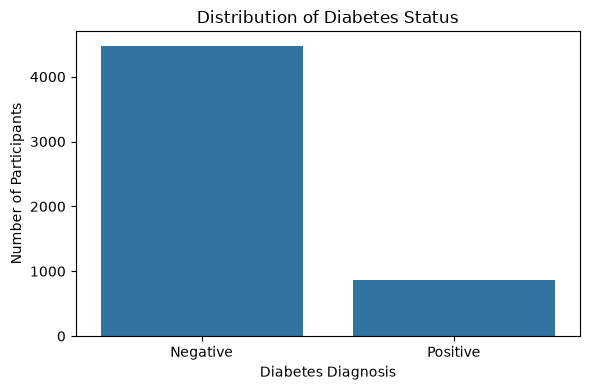

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns

#Show percent with and without diabetes
counts = adult_nhanes['diabetes'].value_counts().sort_index()
percentages = counts / counts.sum() * 100
print(f"Negative: {percentages[0]:.1f}%")
print(f"Positive: {percentages[1]:.1f}%")
print('\n')

# Create a countplot
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=adult_nhanes, x='diabetes')

# Rename x-axis labels
ax.set_xticks([0, 1])
ax.set_xticklabels(['Negative', 'Positive'])

plt.title('Distribution of Diabetes Status')
plt.xlabel('Diabetes Diagnosis')
plt.ylabel('Number of Participants')

plt.tight_layout()
plt.show()

### Summary of Diabetes EDA
This figure shows the distribution of diabetes status in the final dataset. Approximately 16.3% of participants reported diabetes or borderline diabetes, while 83.7% did not. Although the target is moderately imbalanced with only 1/6 having a positive diagnoses, the positive class remains well represented with over 800 observations, providing sufficient data for model development.

### Analysis of Sex Variable



Male: 45.8%
Female: 54.2%




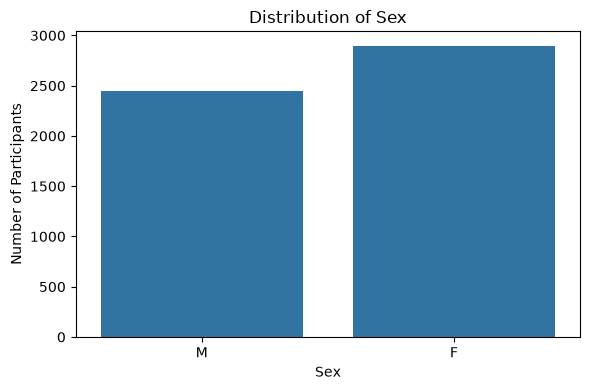

,Diabetes Rate (%)
sex,
F,15.26
M,17.44


In [108]:
#Show percents of male and female respondents
print('\n')
sex_counts = adult_nhanes['sex'].value_counts().sort_index()
sex_percent = sex_counts / sex_counts.sum() * 100
print(f"Male: {sex_percent['M']:.1f}%")
print(f"Female: {sex_percent['F']:.1f}%")
print('\n')

# Create and show a countplot
plt.figure(figsize=(6, 4))
sns.countplot(data=adult_nhanes, x='sex')

plt.title('Distribution of Sex')
plt.xlabel('Sex')
plt.ylabel('Number of Participants')

plt.tight_layout()
plt.show()
print('\n')

#Calculate and display the diabetes rate by sex
sex = (
    adult_nhanes.groupby('sex')['diabetes'].mean()
    *100).round(2).to_frame(name='Diabetes Rate (%)')

display(sex)

### Summary of Sex EDA
This analysis illustrates that the dataset contains a relatively balanced distribution of male and female participants, reducing the likelihood that model performance will be influenced by unequal representation. It also demonstrates that males have a slightly higher rate of diabetes than females. This result is consistent with observations commonly reported in adult populations.

### Analysis of Race



White:    3264, 61.1%
Hispanic: 877,  16.4%
Black:    607,  11.4%
Other:    354,  6.6%
Asian:    243,  4.5%




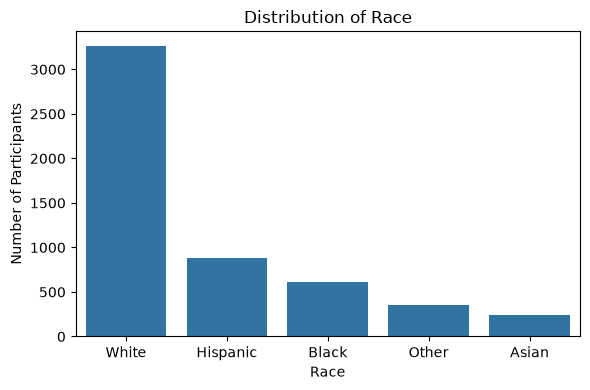

,Diabetes Rate (%)
race,
Black,22.08
Other,19.49
Hispanic,17.33
White,14.77
Asian,13.17


In [120]:
#Show counts and percentage of each racial category
race_counts = adult_nhanes['race'].value_counts()
race_percent = race_counts / race_counts.sum() * 100

print(f"White:    {race_counts['White']}, {race_percent['White']:.1f}%")
print(f"Hispanic: {race_counts['Hispanic']},  {race_percent['Hispanic']:.1f}%")
print(f"Black:    {race_counts['Black']},  {race_percent['Black']:.1f}%")
print(f"Other:    {race_counts['Other']},  {race_percent['Other']:.1f}%")
print(f"Asian:    {race_counts['Asian']},  {race_percent['Asian']:.1f}%")
print('\n')

race_order = ['White', 'Hispanic', 'Black', 'Other', 'Asian']

# Create and show a countplot displaying races in the order specified
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=adult_nhanes, x='race', order=race_order)

plt.title('Distribution of Race')
plt.xlabel('Race')
plt.ylabel('Number of Participants')

plt.tight_layout()
plt.show()
print('\n')

#Calculate and display the diabetes rate for each race
race = (
    adult_nhanes.groupby('race')['diabetes'].mean()
    *100).round(2).sort_values(ascending=False).to_frame(name='Diabetes Rate (%)')

display(race)

### Summary of Race EDA
The racial distribution is moderately imbalanced, with White participants representing the majority of cases. However, all racial categories have sufficient observations for modeling. Diabetes prevalence varies across racial groups, ranging from 13.2% among Asian participants to 22.1% among Black participants. This suggests that race may provide useful predictive information for modeling. However, it is important to realize that differences in the prevalence of diabetes, may be a result of the racial groups having different average characteristics for other features such as BMI, income or age. These initial differences cannot be attributed only to race itself.

### Analysis of Age

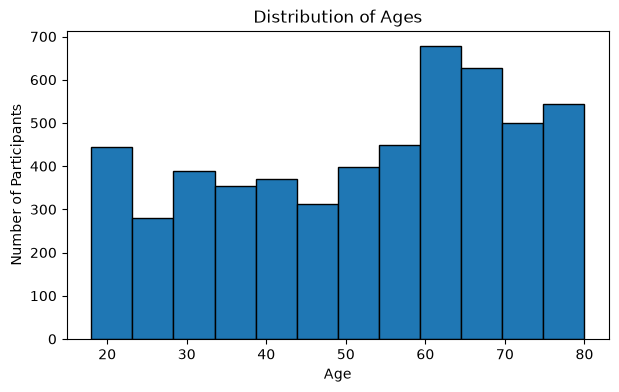

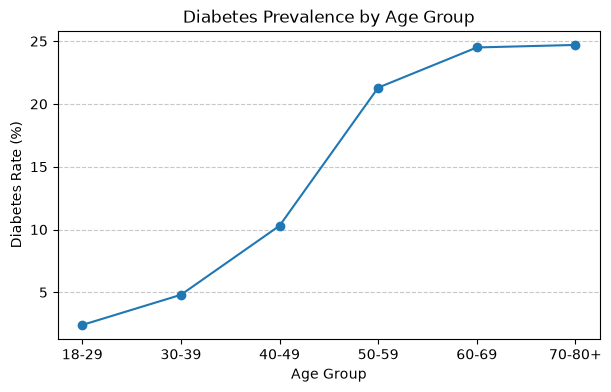

,Diabetes Rate (%)
age,
18-29,2.4
30-39,4.8
40-49,10.3
50-59,21.3
60-69,24.5
70-80+,24.7


In [127]:
#Create a Histogram for age
plt.figure(figsize=(7,4))
plt.hist(adult_nhanes['age'], bins=12, edgecolor='black')

plt.title('Distribution of Ages')
plt.xlabel('Age')
plt.ylabel('Number of Participants')
plt.show()

print('\n')

#Create age groups for plotting
age_group = pd.cut(adult_nhanes['age'],
                                   bins=[18,30,40,50,60,70,81],
                                   labels=['18-29', '30-39', '40-49', '50-59', '60-69', '70-80+'],
                                   right=False)

#Calculate the diabetes rate for each age group
age_rate = (adult_nhanes.groupby(age_group, observed=True)['diabetes'].mean()
            *100).round(1)

#Plot diabetes rate vs age group
plt.figure(figsize=(7,4))
plt.plot(age_rate.index.astype(str), age_rate.values, marker='o')

plt.title('Diabetes Prevalence by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Diabetes Rate (%)')

#Add gridlines to the plot
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()
print('\n')
display(age_rate.to_frame(name='Diabetes Rate (%)'))

### Summary of Age EDA
The ages are well distributed, with the greatest number of participants being between 60 and 70 years old. Diabetes prevalence increases with age in an S-shaped pattern with the sharpest increase being between the groups of 40-49 and 50-59. These results indicate that age is a strong indicator of diabetes risk.

### Analysis of BMI

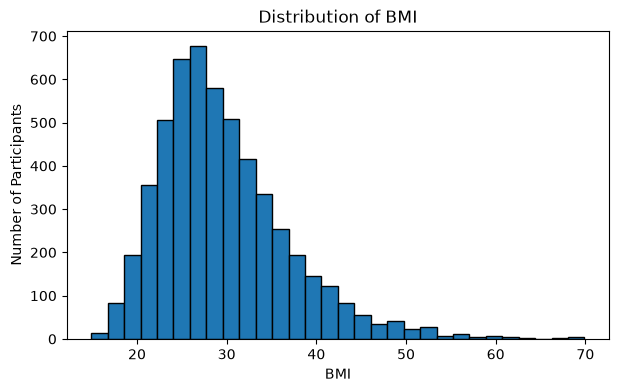

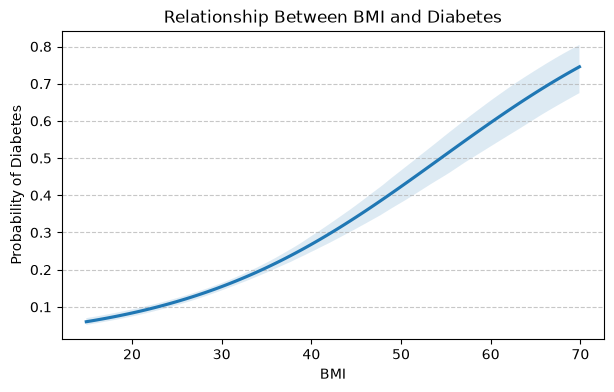

In [130]:
#Create a Histogram for BMI
plt.figure(figsize=(7,4))
plt.hist(adult_nhanes['bmi'], bins=30, edgecolor='black')

plt.title('Distribution of BMI')
plt.xlabel('BMI')
plt.ylabel('Number of Participants')
plt.show()

print('\n')

#Plot a trendline displaying BMI vs diabetes prevalence
plt.figure(figsize=(7,4))

#Use logistic regression for the trendline and don't show the data points
sns.regplot(data=adult_nhanes, x='bmi', y='diabetes',
            logistic=True, scatter=False)

plt.title('Relationship Between BMI and Diabetes')
plt.xlabel('BMI')
plt.ylabel('Probability of Diabetes')

#Add gridlines to the plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### Summary of BMI EDA
The distribution of BMI is approximately bell-shaped but right skewed, with the highest concentration of participants possessing BMI values between approximately 24 and 30. A long right tail extends out toward higher BMI values, indicating there's a small group of individuals with severe obesity. A regression plot shows that the prevalence of diabetes is below 10% when BMI is low and increases in a nonlinear fashion up to 75% as BMI approaches 70. This relationship suggests that BMI may be a strong predictor of diabetes risk.

### Analysis of Income

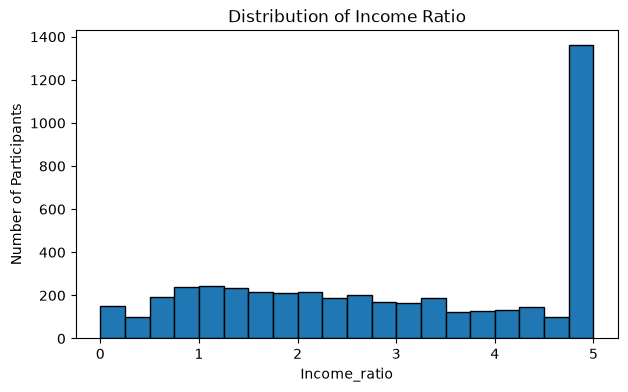

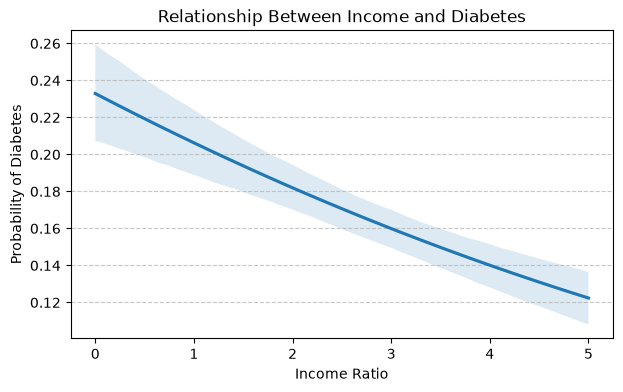

In [150]:
#Create a Histogram for income
plt.figure(figsize=(7,4))
plt.hist(adult_nhanes['income_ratio'], bins=20, edgecolor='black')

plt.title('Distribution of Income Ratio')
plt.xlabel('Income_ratio')
plt.ylabel('Number of Participants')
plt.show()
print('\n')


#Plot a trendline displaying income vs diabetes prevalence
plt.figure(figsize=(7,4))

#Use logistic regression for the trendline and don't show the data points
sns.regplot(data=adult_nhanes, x='income_ratio', y='diabetes',
            logistic=True, scatter=False)

plt.title('Relationship Between Income and Diabetes')
plt.xlabel('Income Ratio')
plt.ylabel('Probability of Diabetes')

#Add gridlines to the plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()
print('\n')

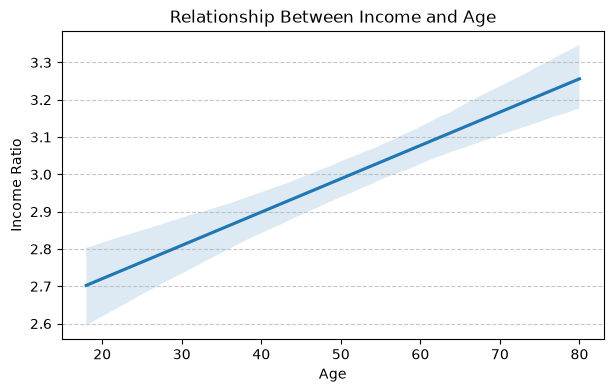

,Income Ratio
race,
Asian,3.62
White,3.33
Other,2.44
Hispanic,2.35
Black,2.22


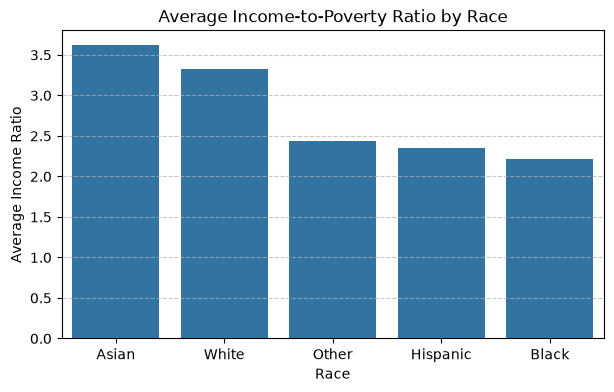

In [149]:
#Plot a trendline displaying income vs age 
plt.figure(figsize=(7,4))

#Use logistic regression for the trendline and don't show the data points
sns.regplot(data=adult_nhanes, x='age', y='income_ratio', scatter=False)

plt.title('Relationship Between Income and Age')
plt.xlabel('Age')
plt.ylabel('Income Ratio')

#Add gridlines to the plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()
print('\n')


#Calculate the average income to poverty ratio for each race
incomes = (
    adult_nhanes.groupby('race')['income_ratio'].mean()
    .round(2).sort_values(ascending=False).to_frame(name='Income Ratio') )

display(incomes)
print('\n')

#Create a barplot of average income ratio for each racial group.
plt.figure(figsize=(7,4))
sns.barplot(x=incomes.index, y=incomes['Income Ratio'])

plt.title("Average Income-to-Poverty Ratio by Race")
plt.xlabel("Race")
plt.ylabel("Average Income Ratio")

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

### Summary of Income EDA
The income-to-poverty ratio is relatively well distributed across most of its range, with a pronounced concentration of participants at the maximum recorded value of 5. This is partly due to top-coding. The prevalence of diabetes decreases as the income-to-poverty ratio increases. Although the effect is smaller than that observed for age and BMI, this trend suggests that socioeconomic status is an important predictor of diabetes risk. 

A modest positive relationship exists between age and income to poverty ratio. This indicates that income generally increases with age. The average income of participants also appears to differ across racial groups. Asian and white participants have the highest incomes with the other three groups having a substantially lower average income. These observed associations between income, age, and race offer support for the idea that demographic characteristics should be used when imputing missing income values.

### Analysis of Weekly Exercise

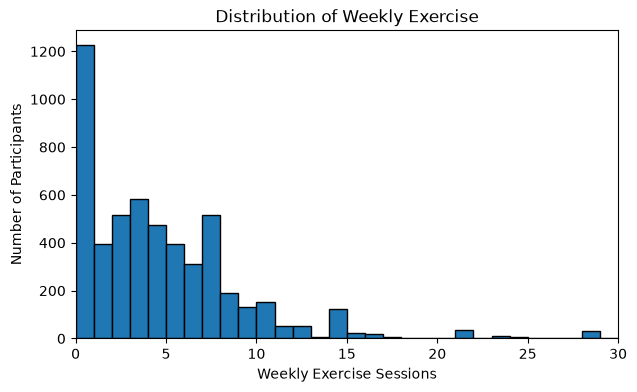

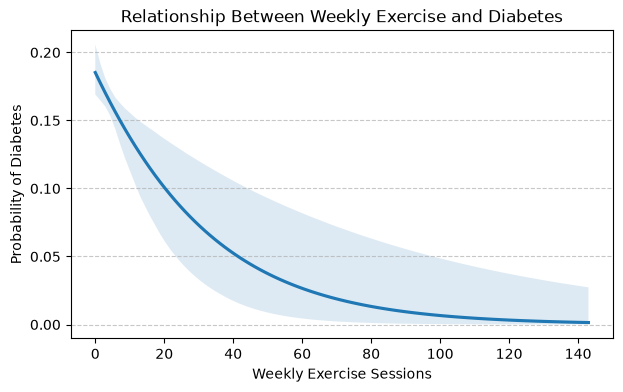

In [148]:
#Create a Histogram for weekly exercise, bins is set to the maximum number of sessions per week.
#This renders a clean diagram with each bar representing an incremental increase of one session per week.
plt.figure(figsize=(7,4))
plt.hist(adult_nhanes['weekly_exercise'], bins=143, edgecolor='black')

#Limit the range of visualization to a maximum of 30 sessions per week to improve readability.
plt.xlim(0, 30)

plt.title('Distribution of Weekly Exercise')
plt.xlabel('Weekly Exercise Sessions')
plt.ylabel('Number of Participants')
plt.show()
print('\n')

#Plot a trendline displaying exercise vs diabetes prevalence
plt.figure(figsize=(7,4))

#Use logistic regression for the trendline and don't show the data points
sns.regplot(data=adult_nhanes, x='weekly_exercise', y='diabetes',
            logistic=True, scatter=False)

plt.title('Relationship Between Weekly Exercise and Diabetes')
plt.xlabel('Weekly Exercise Sessions')
plt.ylabel('Probability of Diabetes')

#Add gridlines to the plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()
print('\n')

### Summary of Weekly Exercise EDA
There is a non-linear relationship between weekly exercise sessions and diabetes risk. The prevalence of diabetes decreases sharply at first as weekly exercise increases, and then begins to level off when there is more than 40 sessions per week. Beyond this point the curve begins to flatten, indicating diminishing reductions in diabetes rate despite additional exercise.These findings suggest that increasing physical activity is associated with a lower risk of diabetes, although the incremental benefit decreases at higher exercise frequencies.

### Analysis of Sedentary Minutes

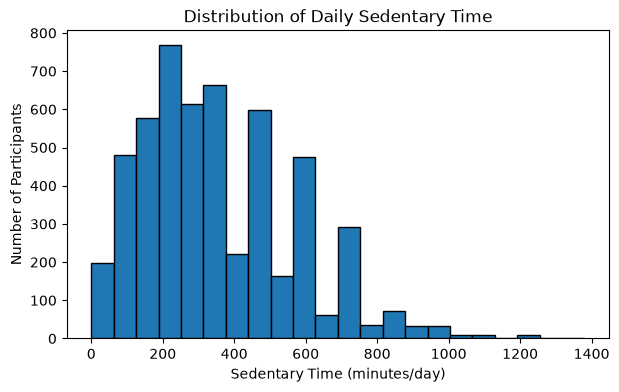

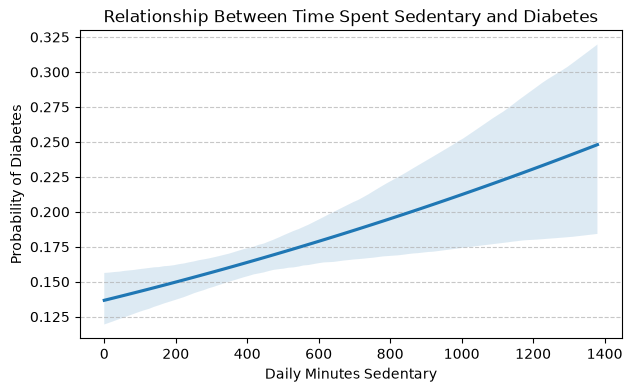

In [166]:
#Create histogram of sedentary minutes.
plt.figure(figsize=(7,4))
plt.hist(adult_nhanes['sedentary_mins'], bins=22, edgecolor='black')

plt.title('Distribution of Daily Sedentary Time')
plt.xlabel('Sedentary Time (minutes/day)')
plt.ylabel('Number of Participants')

plt.show()
print('\n')

#Plot a trendline displaying sedentary minutes vs diabetes prevalence
plt.figure(figsize=(7,4))

#Use logistic regression for the trendline and don't show the data points
sns.regplot(data=adult_nhanes, x='sedentary_mins', y='diabetes',
            logistic=True, scatter=False)

plt.title('Relationship Between Time Spent Sedentary and Diabetes')
plt.xlabel('Daily Minutes Sedentary')
plt.ylabel('Probability of Diabetes')

#Add gridlines to the plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()
print('\n')

### Summary of Sedentary EDA
Daily sedentary time demonstrates a positive association with diabetes prevalence. The distribution shows evidence of response heaping, with participants frequently reporting rounded values, which is common for self-reported behavioral variables. The logistic regression trend shows a generally linear increase in diabetes probability as sedentary time increases. Compared with exercise frequency, sedentary time demonstrates a weaker association, suggesting that both physical activity and sedentary behavior may provide complementary but distinct information for predicting diabetes status.

### Heatmap of numeric variables

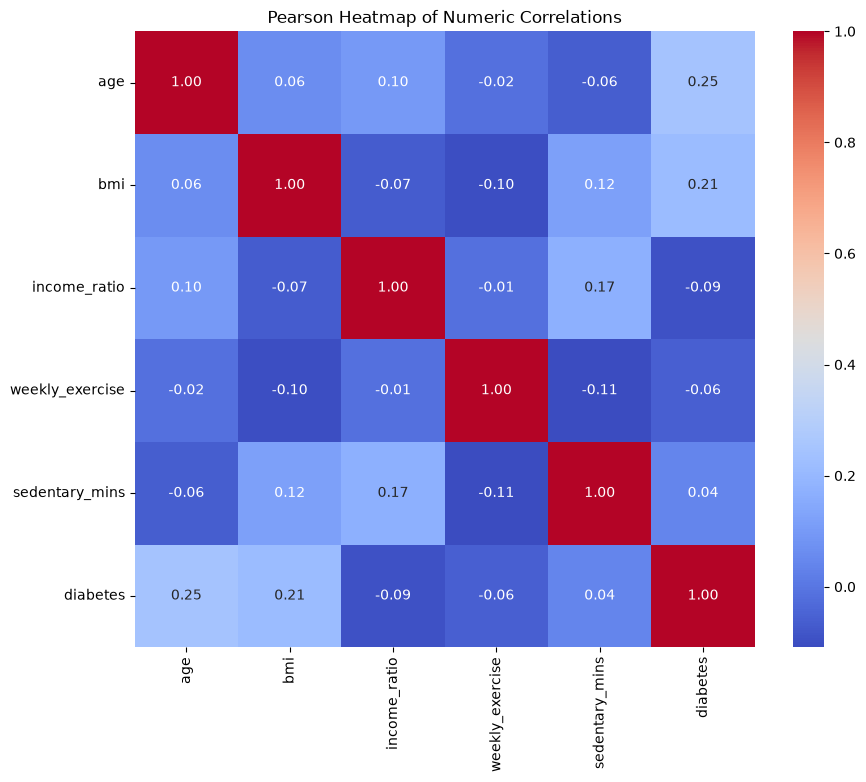

,age,bmi,income_ratio,weekly_exercise,sedentary_mins,diabetes
age,1.000000,0.087122,0.084662,-0.069969,-0.055190,0.239718
bmi,0.087122,1.000000,-0.059978,-0.205032,0.093533,0.216937
income_ratio,0.084662,-0.059978,1.000000,0.093771,0.198258,-0.099343
weekly_exercise,-0.069969,-0.205032,0.093771,1.000000,-0.128663,-0.138417
sedentary_mins,-0.055190,0.093533,0.198258,-0.128663,1.000000,0.040324
diabetes,0.239718,0.216937,-0.099343,-0.138417,0.040324,1.000000


In [169]:
#Create List of numeric variables.
numeric_variables = ['age', 'bmi', 'income_ratio', 'weekly_exercise', 'sedentary_mins', 'diabetes']

#Plot a heatmap of the numeric feature correlations.
plt.figure(figsize = (10,8))
sns.heatmap(adult_nhanes[numeric_variables].corr(
    method='pearson'), annot=True, fmt=".2f", cmap="coolwarm") 

plt.title("Pearson Heatmap of Numeric Correlations")
plt.show()
print('\n')

#Run Spearman correlations to compare results.
spearman = adult_nhanes[numeric_variables].corr(method='spearman')
display(spearman)

### Summary of Numeric Correlations
Pearson correlation analysis reveals that age and BMI have the strongest positive linear associations with diabetes, while income ratio and weekly exercise demonstrate weak negative correlations. Sedentary time shows only a very weak positive linear association. The relatively small coefficients are expected because several predictors exhibit nonlinear relationships with diabetes prevalence during EDA. Spearman correlation analysis which better captures monotonic relationships that are not necessarily linear produced similar results with the exception of weekly exercise. The spearman correlation for weekly exercise is -0.14 compared to -0.06. These results support retaining the numeric variables for multivariable modeling, since weak marginal correlations do not necessarily imply that a feature lacks predictive value..

### Analysis of Smoking



Have You Smoked 100 Cigarettes?


No: 60.5%
Yes: 39.5%




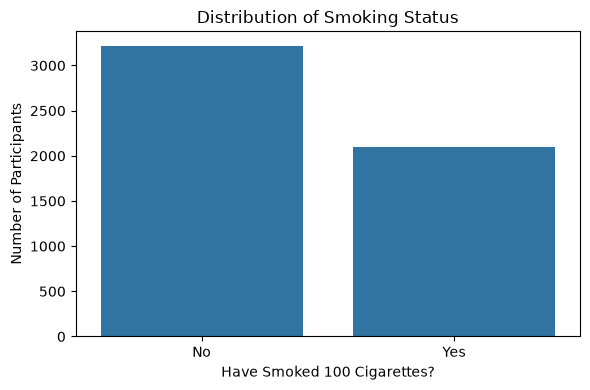

,Diabetes Rate (%)
No,13.09
Yes,21.02


In [178]:
#Show the percent who have smoked more than 100 cigarettes and have not.
print('\n')
smoked_counts = adult_nhanes['smoked_100'].value_counts().sort_index()
smoked_percent = smoked_counts / smoked_counts.sum() * 100

print("Have You Smoked 100 Cigarettes?")
print('\n')
print(f"No: {smoked_percent[0]:.1f}%")
print(f"Yes: {smoked_percent[1]:.1f}%")
print('\n')

# Create and show countplot
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=adult_nhanes, x='smoked_100')

#Set 0 as No and 1 as Yes in the plot
ax.set_xticks([0, 1])
ax.set_xticklabels(['No', 'Yes'])

plt.title('Distribution of Smoking Status')
plt.xlabel('Have Smoked 100 Cigarettes?')
plt.ylabel('Number of Participants')

plt.tight_layout()
plt.show()
print('\n')

#Calculate and display the diabetes rate by smoking status
smoked = (
    adult_nhanes.groupby('smoked_100')['diabetes'].mean()
    *100).round(2).to_frame(name='Diabetes Rate (%)')

#Display 0 as No and 1 as Yes in the dataframe
smoked.index = ['No', 'Yes']

display(smoked)

### Summary of Smoking EDA
Approximately 40% of participants reported having smoked at least 100 cigarettes during their lifetime. Participants with a history of smoking demonstrated a higher prevalence of diabetes compared to those who have never smoked, 21% vs 13%. This represents an absolute difference of approximately 8 percentage points, suggesting that smoking history may provide predictive value when modeling diabetes risk.

### Analysis of Heavy Drinking



Have You Ever Drank 4/5 Drinks Per Day Every Day?


No: 83.2%
Yes: 16.8%




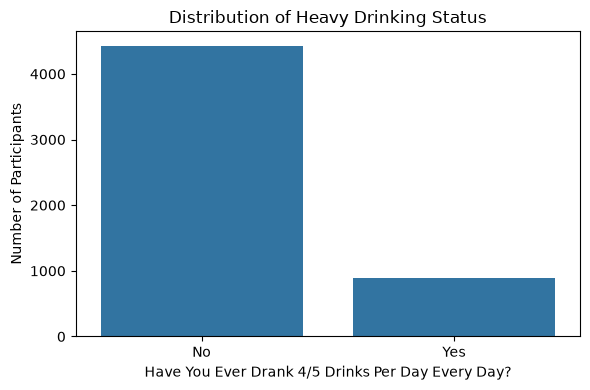

,Diabetes Rate (%)
No,15.18
Yes,21.39


In [181]:
#Show the percent of those who have drank heavily before and those who have not.
print('\n')
heavy_counts = adult_nhanes['drank_heavily'].value_counts().sort_index()
heavy_percent = heavy_counts / heavy_counts.sum() * 100

print("Have You Ever Drank 4/5 Drinks Per Day Every Day?")
print('\n')
print(f"No: {heavy_percent[0]:.1f}%")
print(f"Yes: {heavy_percent[1]:.1f}%")
print('\n')

# Create and show countplot
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=adult_nhanes, x='drank_heavily')

#Set 0 as No and 1 as Yes in the plot
ax.set_xticks([0, 1])
ax.set_xticklabels(['No', 'Yes'])

plt.title('Distribution of Heavy Drinking Status')
plt.xlabel('Have You Ever Drank 4/5 Drinks Per Day Every Day?')
plt.ylabel('Number of Participants')

plt.tight_layout()
plt.show()
print('\n')

#Calculate and display the diabetes rate by drinking status
heavily = (
    adult_nhanes.groupby('drank_heavily')['diabetes'].mean()
    *100).round(2).to_frame(name='Diabetes Rate (%)')

#Display 0 as No and 1 as Yes in the dataframe
heavily.index = ['No', 'Yes']

display(heavily)

### Summary of Heavy Drinking EDA
Approximately 16.8% of participants reported consuming four to five alcoholic drinks daily at one point in their life. Participants reporting this level of heavy alcohol consumption demonstrated a higher prevalence of diabetes compared to those who did not report heavy consumption, 21.4% vs. 15.2%. This is a nominal difference of approximately 6.2 percentage points suggesting that heavy alcohol consumption may provide additional predictive information, although the separation is slightly lower than that of smoking.

### Analysis of ever_drank Feature



Have You Ever Drank Alcohol?


No: 10.1%
Yes: 89.9%




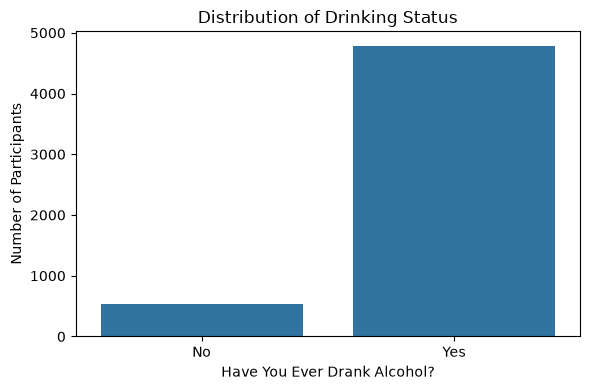

,Diabetes Rate (%)
No,19.81
Yes,15.82


In [182]:
#Show the percent of those who have drank alcohol before and those who have not.
print('\n')
drank_counts = adult_nhanes['ever_drank'].value_counts().sort_index()
drank_percent = drank_counts / drank_counts.sum() * 100

print("Have You Ever Drank Alcohol?")
print('\n')
print(f"No: {drank_percent[0]:.1f}%")
print(f"Yes: {drank_percent[1]:.1f}%")
print('\n')

# Create and show countplot
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=adult_nhanes, x='ever_drank')

#Set 0 as No and 1 as Yes in the plot
ax.set_xticks([0, 1])
ax.set_xticklabels(['No', 'Yes'])

plt.title('Distribution of Drinking Status')
plt.xlabel('Have You Ever Drank Alcohol?')
plt.ylabel('Number of Participants')

plt.tight_layout()
plt.show()
print('\n')

#Calculate and display the diabetes rate by drinking status
drank = (
    adult_nhanes.groupby('ever_drank')['diabetes'].mean()
    *100).round(2).to_frame(name='Diabetes Rate (%)')

#Display 0 as No and 1 as Yes in the dataframe
drank.index = ['No', 'Yes']

display(drank)

### Summary of Ever Drank EDA
Lifetime alcohol consumption demonstrated an unexpected inverse relationship with diabetes prevalence. However, this feature is very limited because it does not represent a clinically significant behavior. Individuals classified as "ever drank" may include participants with minimal lifetime exposure. To analyze this feature further, the possibility of confounding factors will be investigated.

### Investigation of Confounding Factors 

In [191]:
#Calculate the average income ratio by drinking status, and convert to a data frame.
drank_income = (
    adult_nhanes.groupby('ever_drank')['income_ratio'].mean()
        .round(2).to_frame(name='Income Ratio') )

#Display 0 as No and 1 as Yes.
drank_income.index = ['No', 'Yes']
display(drank_income)

print('\n')

#Calculate the percentage that has drank versus not drank for each race.
drank_race = pd.crosstab(
    adult_nhanes['race'],
    adult_nhanes['ever_drank'],
    normalize='index').round(2)

#rename the columns of 0 and 1 to Yes and No.
drank_race.columns = ['No', 'Yes']

display(drank_race)

,Income Ratio
No,2.23
Yes,3.10


,No,Yes
race,,
Asian,0.26,0.74
Black,0.14,0.86
Hispanic,0.14,0.86
Other,0.09,0.91
White,0.07,0.93


### Confounding Factors Results
Participants who reported never drinking alcohol were disproportionately non-White. Because diabetes prevalence differs across racial groups, these differences likely contribute to the observed association between lifetime alcohol use and diabetes. Also, participants who reported never drinking had substantially lower average income ratios, 2.23 vs. 3.10, providing another likely source of confounding. Since this variable does not represent a clinically meaningful measure of alcohol consumption and appears to be influenced by multiple confounding factors, 'ever_drank' will be excluded from modeling.

In [211]:
#Remove the ever_drank feature.
adult_nhanes = adult_nhanes.drop(columns = ['ever_drank'])

#View the dataset
display(adult_nhanes.head(7))

,SEQN,diabetes,age,sex,race,income_ratio,bmi,smoked_100,drank_heavily,weekly_exercise,sedentary_mins
1,130379,0,66,M,White,5.00,33.5,1,0,7.0,480
2,130380,1,44,F,Hispanic,1.41,29.7,0,0,1.0,240
8,130386,0,34,M,Hispanic,1.33,30.2,1,0,1.231,180
9,130387,0,68,F,White,1.32,42.6,0,0,0.0,1200
11,130389,0,59,M,White,5.00,28.0,1,0,3.462,720
13,130391,0,33,F,White,0.93,38.9,1,0,28.0,240
14,130392,0,74,F,White,3.04,43.0,0,0,0.0,300


## Train-Test-Split
The target variable is separated from feature variables and the data set is divided into a training set and a test set. Splitting the data before fitting preprocessing steps helps prevent data leakage by ensuring that information from the test set is not used during model training. 80% of the data will be used for training and 20% will be used for model validation.

In [212]:
from sklearn.model_selection import train_test_split

#Create variables identifying the target and the features.
y = adult_nhanes['diabetes']
X = adult_nhanes.drop(columns = ['diabetes'])

#Split the data into a training set and test set. Stratification ensures both sets have the same proportion
#of positive and negative diabetes cases.
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=12)

## Custom Imputation Transformer for Income

A custom transformer is created to impute missing income ratios based on the age group and race for a participant. Median income ratios are calculated for each age-group/race combination using only the training data which prevents data leakage from the test set reaching the training set. The racial median values are used as fallback values when an age-group/race combination is unavailable. Race is used as the fallback because EDA showed it has a stronger association with income_ratio than age and greater separation between the categories for race was observed.

In [223]:
from sklearn.base import BaseEstimator, TransformerMixin

#Initialize custom transformer class
class IncomeImputer(BaseEstimator, TransformerMixin):
    
    #Define age brackets
    def __init__(self):
        self.bins = [17, 29, 39, 49, 59, 69, 80]

    #Create a method to create the age brackets
    def get_age_brackets(self, ages):
        return pd.cut(ages, bins=self.bins)

    #Define the fit method
    def fit(self, X, y=None):

        X_fit = X.copy()
        X_fit['age_bracket'] = self.get_age_brackets(X_fit['age'])

        #Learn medians from training data only
        self.race_age_medians_ = (
            X_fit.groupby(['age_bracket', 'race'], observed=True)['income_ratio'].median() )

        self.race_medians_ = (
            X_fit.groupby('race')['income_ratio'].median() )

        return self

    #Define the transform method
    def transform(self, X):

        X_clean = X.copy()
        X_clean['age_bracket'] = self.get_age_brackets(X_clean['age'])

        #Look up age + race median
        primary_lookup = (
            X_clean.set_index(['age_bracket', 'race']).index
            .map(self.race_age_medians_) )

        #Look up race-only median as fallback
        fallback_lookup = X_clean['race'].map(self.race_medians_)

        #Impute using age + race, then race if necessary
        X_clean['income_ratio'] = (
            X_clean['income_ratio']
            .fillna(pd.Series(primary_lookup, index=X_clean.index))
            .fillna(fallback_lookup) )

        #Remove temporary grouping column and race column from the numeric columns
        return X_clean.drop(columns=['age_bracket', 'race'])
    
    #Allow the custom transformer to work with get_feature_names_out.
    def get_feature_names_out(self, input_features=None):
        return np.array([
            feature for feature in input_features
            if feature != 'race'])

### Column List Creation
#### Feature column lists are created for each feature type. These lists will be used by the preprocessing pipelines.

In [213]:
#Create a list for each feature type that will be used in preprocessing pipelines.
numeric_columns = ['age', 'bmi', 'income_ratio', 'weekly_exercise', 'sedentary_mins']

binary_columns = ['smoked_100', 'drank_heavily']

categorical_columns = ['sex', 'race']

## Creation of Preprocessing Pipelines

Separate Preprocessing pipelines are created for numeric, categorical and binary features. A column transformer is used to combine these pipelines so that each feature type receives the appropriate preprocessing. The full pipeline is fit to the training data and used to transform both the training and test sets.

In [227]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler 
from sklearn.preprocessing import OneHotEncoder 
from sklearn.compose import ColumnTransformer


# Include race so IncomeImputer can use it when imputing income.
income_imputer_columns = numeric_columns + ['race']

#Create numeric preprocessing pipeline which imputes missing values and scales the features.
numeric_pipeline = make_pipeline(IncomeImputer(), StandardScaler() )

#Create categorical preprocessing pipeline using one-hot encoding.
#Use drop='first' to prevent multicollinearity between feature categories.
categorical_pipeline = OneHotEncoder(drop='first')

#Create full preprocessing pipeline which combines the column specific pipelines.
full_pipeline = make_pipeline(ColumnTransformer([
    ('num', numeric_pipeline, income_imputer_columns),
    ('cat', categorical_pipeline, categorical_columns),
    ('bin', 'passthrough', binary_columns)]) )

#Fit the preprocessing pipeline using training data and transform the training data.
X_train_transformed = full_pipeline.fit_transform(x_train)

#Transform the test data using the fitted pipeline.
X_test_transformed = full_pipeline.transform(x_test)

### Inspect the Transformed Dataset

It is important to inspect the transformed training data to verify that each component of the pipeline is functioning properly.

In [228]:
#Verify dimensions of the transformed dataset
print('Shape: ', X_train_transformed.shape) 
print('\n')

#Create a dataframe from X_train_transformed with feature names intact
feature_names = full_pipeline.named_steps['columntransformer'].get_feature_names_out() 
df_train = pd.DataFrame(X_train_transformed, columns=feature_names)

#Verify that there are no missing values
print('Missing Values: ', df_train.isna().sum().sum())
print('\n')

#Transpose the dataframe to view features vertically
display(df_train.head(8).T)

Shape:  (4256, 12)


Missing Values:  0




,0,1,2,3,4,5,6,7
num__age,1.538181,1.317281,-0.229023,-1.830553,1.538181,-1.333526,-1.167851,1.538181
num__bmi,0.1338,0.188695,-0.072056,0.339657,-0.003437,-0.291636,3.660808,0.229867
num__income_ratio,0.249284,0.192417,1.272895,1.272895,0.192417,-0.584769,-1.342999,-1.418822
num__weekly_exercise,0.268168,-0.399608,0.268168,-0.132498,0.268168,-0.266053,-0.142648,-0.666719
num__sedentary_mins,0.823449,-0.05491,-0.05491,-0.347696,-0.640482,-0.640482,1.116235,-0.347696
cat__sex_M,1.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0
cat__race_Black,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
cat__race_Hispanic,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
cat__race_Other,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
cat__race_White,0.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0


## Modeling & Evaluation

To begin modeling, model types must be selected. In this project, the model types used will be: Logistic Regression, SVM Classifier, Decision Tree Classifier, Gradient Boosting Classifier and MLP Classifier(neural network). These models each use different approaches, which allows them to be more or less reliable, depending on the relationships in the data. Logistic regression performs well when the relationships are linear while gradient boosting can capture relationships that are nonlinear as well as interactions between variables. A neural network is often best when the relationships are non-linear and very complex. However, using a more powerful model does not always yield better results and may lead to overfitting.

Because this is a binary classification problem and the goal is to estimate diabetes risk probabilities, model performance will be evaluated using ROC AUC, Log Loss, and Brier Score.

In [232]:
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression 
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier

#Instantiate the Logistic Regression Model
log_reg = LogisticRegression()

#Instantiate a Support Vector Classifier Model
svm_clf = CalibratedClassifierCV(SVC(), ensemble=False)

#Instantiate a Decision Tree Classifier Model with a max depth of 6
tree_clf = DecisionTreeClassifier(max_depth=6, random_state=12)

#Instantiate a Gradient Boosting Classifier Model with basic hyper parameters
gb_clf = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05,
max_depth=3, min_samples_leaf=5, subsample=0.8, random_state=12)

#Calculate ROC AUC scores using 5-fold cross-validation
roc_log_reg = cross_val_score(
    log_reg, X_train_transformed, y_train,
    cv=5, scoring='roc_auc')

roc_svm = cross_val_score(
    svm_clf, X_train_transformed, y_train,
    cv=5, scoring='roc_auc')

roc_tree = cross_val_score(
    tree_clf, X_train_transformed, y_train,
    cv=5, scoring='roc_auc')

roc_gb = cross_val_score(
    gb_clf, X_train_transformed, y_train,
    cv=5, scoring='roc_auc')

#Calculate Log Loss scores using 5-fold cross-validation
los_log_reg = cross_val_score(
    log_reg, X_train_transformed, y_train,
    cv=5, scoring='neg_log_loss')

los_svm = cross_val_score(
    svm_clf, X_train_transformed, y_train,
    cv=5, scoring='neg_log_loss')

los_tree = cross_val_score(
    tree_clf, X_train_transformed, y_train,
    cv=5, scoring='neg_log_loss')

los_gb = cross_val_score(
    gb_clf, X_train_transformed, y_train,
    cv=5, scoring='neg_log_loss')

#Calculate Brier scores using 5-fold cross-validation
br_log_reg = cross_val_score(
    log_reg, X_train_transformed, y_train,
    cv=5, scoring='neg_brier_score')

br_svm = cross_val_score(
    svm_clf, X_train_transformed, y_train,
    cv=5, scoring='neg_brier_score')

br_tree = cross_val_score(
    tree_clf, X_train_transformed, y_train,
    cv=5, scoring='neg_brier_score')

br_gb = cross_val_score(
    gb_clf, X_train_transformed, y_train,
    cv=5, scoring='neg_brier_score')

#Create a dataframe of the scores
scores_df = pd.DataFrame({
    'ROC AUC': {
        'Logistic Regression': roc_log_reg.mean(),
        'SVM': roc_svm.mean(),
        'Decision Tree': roc_tree.mean(),
        'Gradient Boosting': roc_gb.mean() },
    'Log Loss': {
        'Logistic Regression': -los_log_reg.mean(),
        'SVM': -los_svm.mean(),
        'Decision Tree': -los_tree.mean(),
        'Gradient Boosting': -los_gb.mean() },
    'Brier Score': {
        'Logistic Regression': -br_log_reg.mean(),
        'SVM': -br_svm.mean(),
        'Decision Tree': -br_tree.mean(),
        'Gradient Boosting': -br_gb.mean()} })
    

#Display the dataframe of scores
display(scores_df.round(3))

,ROC AUC,Log Loss,Brier Score
Logistic Regression,0.774,0.377,0.119
SVM,0.678,0.424,0.130
Decision Tree,0.736,0.719,0.131
Gradient Boosting,0.776,0.378,0.119


## Initial Model Evaluation

The initial results show that Logistic Regression and Gradient Boosting are the strongest-performing models. Gradient Boosting produced the highest ROC AUC (0.776), while Logistic Regression was nearly identical at (0.774). Both models also produced nearly identical Log Loss and Brier Scores, indicating similar probability quality. SVC performed worse across all three metrics, while the Decision Tree produced reasonable discrimination but substantially poorer probability estimates.

ROC AUC: Measures how well a model distinguishes participants with diabetes from those without diabetes across different classification thresholds, with higher values indicating better discrimination. 

Log Loss: Measures the accuracy of predicted probabilities and heavily penalizes confident incorrect predictions. Lower values are better. 

 Brier Score: Measures the difference between predicted probabilities and the actual outcomes with standard scoring. Lower values indicate better-calibrated predictions.

Since Logistic Regression and Gradient Boosting models are currently performing similarly, further evaluation and hyperparameter tuning will be used to determine whether Gradient Boosting can provide a meaningful improvement over the simpler Logistic Regression model.

It is important to note here that it would be more rigorous to run cross validation on x_train using the full preprocessing pipeline in each fold. However, the data leakage effect in this scenario is expected to be very limited. Also, the test set remains completely isolated from preprocessing and training, leaving it reserved for final model evaluation.

# Create and Compile a Neural Network

The first step is to create and compile a neural network. The initial neural network uses a relatively simple architecture because the transformed dataset contains only 12 features. It consists of an input layer, one hidden layer containing 32 neurons, and a single-neuron output layer. ReLU activation is used in the hidden layer, while sigmoid activation produces binary probability estimates. The model is optimized using Adam with binary cross-entropy loss, with accuracy included as a training metric.

In [233]:
import os
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

#Hide routine TensorFlow messages
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'

#Instantiate the sequential model.
neural_network = Sequential()


#Create the input layer accepting 12 features as input.
neural_network.add(Input(shape=(12,)))

#Create a hidden layer with 32 neurons.
#Use ReLU activation to allow the network to learn non-linear relationships.
neural_network.add(Dense(32, activation='relu'))

#Create the output layer with 1 neuron.
#Use sigmoid activation to produce probabilities between 0 and 1.
neural_network.add(Dense(1, activation='sigmoid'))

#Compile using the Adam optimizer and binary cross-entropy loss.
neural_network.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy'])

2026-08-14 12:56:26.544891: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2026-08-14 12:56:26.544924: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-08-14 12:56:26.544930: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-08-14 12:56:26.545215: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-08-14 12:56:26.545230: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


## Network Training and Validation

The model is trained and validated using the training set. 80% of the set is used for training and 20% for validation.

In [241]:
#Convert preprocessed features to TensorFlow-compatible numeric arrays.
X_train_nn = np.asarray(X_train_transformed, dtype=np.float32)

#Convert target to a TensorFlow-compatible numeric array.
y_train_nn = y_train.to_numpy(dtype=np.float32)

#Train and validate the model using the training set and validate the model using the training set.
#Set the batch size to 32 and set epochs to 20 for 20 rounds of training. 
#80% of the set is used for training and 20% for validation.
history = neural_network.fit(
    X_train_nn,
    y_train_nn,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    verbose=2 )

Epoch 1/20


2026-08-14 13:53:49.977872: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


107/107 - 9s - 86ms/step - accuracy: 0.6645 - loss: 0.6040 - val_accuracy: 0.8275 - val_loss: 0.4516
Epoch 2/20
107/107 - 1s - 10ms/step - accuracy: 0.8270 - loss: 0.4225 - val_accuracy: 0.8392 - val_loss: 0.3999
Epoch 3/20
107/107 - 1s - 9ms/step - accuracy: 0.8320 - loss: 0.3964 - val_accuracy: 0.8380 - val_loss: 0.3854
Epoch 4/20
107/107 - 1s - 9ms/step - accuracy: 0.8349 - loss: 0.3869 - val_accuracy: 0.8369 - val_loss: 0.3780
Epoch 5/20
107/107 - 1s - 9ms/step - accuracy: 0.8352 - loss: 0.3824 - val_accuracy: 0.8369 - val_loss: 0.3760
Epoch 6/20
107/107 - 1s - 9ms/step - accuracy: 0.8340 - loss: 0.3801 - val_accuracy: 0.8427 - val_loss: 0.3716
Epoch 7/20
107/107 - 1s - 9ms/step - accuracy: 0.8375 - loss: 0.3790 - val_accuracy: 0.8404 - val_loss: 0.3723
Epoch 8/20
107/107 - 1s - 9ms/step - accuracy: 0.8373 - loss: 0.3781 - val_accuracy: 0.8415 - val_loss: 0.3713
Epoch 9/20
107/107 - 1s - 10ms/step - accuracy: 0.8355 - loss: 0.3781 - val_accuracy: 0.8439 - val_loss: 0.3683
Epoch 10/

### Initial Results
The initial neural network produced a validation log loss of 0.367, which is lower than the log loss of the other candidate models. This preliminary result suggests that the neural network may perform competitively on this dataset. To make the neural network directly comparable to the other models, it will now be evaluated using the same 5-fold cross-validation procedure and probability-based evaluation metrics.

## Evaluation of the Neural Network
The neural network is evaluated using 5-fold cross-validation and the same metrics used to evaluate the other candidate models: ROC AUC, Log Loss, and Brier Score. Using the same evaluation procedure allows the neural network's performance to be compared directly with the other models. 

In [248]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

# Define a function that creates a neural network and compiles it.
# A new model is created for each cross-validation fold.
def build_nn():
    model = Sequential([
        Input(shape=(12,)),
        Dense(32, activation='relu'),
        Dense(1, activation='sigmoid') ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy'] )

    return model


# Define 5-fold stratified cross-validation.
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=12)


# Create lists to store the three evaluation metrics.
roc_nn = []
log_nn = []
br_nn = []


# Train and evaluate a separate neural network for each cross-validation fold.
for train_index, val_index in skf.split(X_train_nn, y_train_nn):
    
    # Create a new neural network for the current fold.
    model = build_nn()
    
    # Train the model using the training portion of the current fold.
    model.fit(
        X_train_nn[train_index],
        y_train_nn[train_index],
        epochs=20,
        batch_size=32,
        verbose=0)
    
    # Generate probability predictions for the validation portion.
    # These same predictions will be used for all three evaluation metrics.
    y_prob = model.predict(
        X_train_nn[val_index],
        verbose=0).ravel()
    
    # Calculate ROC AUC.
    roc_nn.append(
        roc_auc_score(y_train_nn[val_index], y_prob))
    
    # Calculate Log Loss.
    log_nn.append(
        log_loss(y_train_nn[val_index], y_prob))
    
    # Calculate Brier Score.
    br_nn.append(
        brier_score_loss(y_train_nn[val_index], y_prob))


#Calculate the mean score across the five validation folds.
roc_nn_mean = np.mean(roc_nn)
log_nn_mean = np.mean(log_nn)
br_nn_mean = np.mean(br_nn)


#Create a dataframe containing the mean cross-validation scores
scores_df2 = pd.DataFrame({
    
    'ROC AUC': {
        'Logistic Regression': roc_log_reg.mean(),
        'SVM': roc_svm.mean(),
        'Decision Tree': roc_tree.mean(),
        'Gradient Boosting': roc_gb.mean(),
        'Neural Network': roc_nn_mean},
    
    'Log Loss': {
        'Logistic Regression': -los_log_reg.mean(),
        'SVM': -los_svm.mean(),
        'Decision Tree': -los_tree.mean(),
        'Gradient Boosting': -los_gb.mean(),
        'Neural Network': log_nn_mean},
    
    'Brier Score': {
        'Logistic Regression': -br_log_reg.mean(),
        'SVM': -br_svm.mean(),
        'Decision Tree': -br_tree.mean(),
        'Gradient Boosting': -br_gb.mean(),
        'Neural Network': br_nn_mean} })


#Display the mean cross-validation scores rounded to three decimals.
display(scores_df2.round(3))

,ROC AUC,Log Loss,Brier Score
Logistic Regression,0.774,0.377,0.119
SVM,0.678,0.424,0.130
Decision Tree,0.736,0.719,0.131
Gradient Boosting,0.776,0.378,0.119
Neural Network,0.772,0.379,0.119


### Initial Model Comparison

Gradient Boosting achieved the best ROC AUC score, while Logistic Regression achieved the best Log Loss. Logistic Regression, Gradient Boosting, and the Neural Network had essentially identical Brier Scores. The neural network performed competitively with the best traditional models but did not provide a substantial improvement in overall performance.

## Model Fine-Tuning

The next step is to fine-tune the best candidate models by performing a Grid Search to determine the most optimal parameters for them. Gradient Boosting is the first model to optimize.

In [249]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

#Define a grid of hyperparameters to test
gradient_grid = {'n_estimators': [100, 200, 300], 
                 'learning_rate': [0.01, 0.05],
                 'max_depth': [2, 3, 4],
                 'min_samples_leaf': [1, 2, 3],
                 'subsample': [0.7, 0.8, 0.9] }

#Instantiate GridSearchCV for Gradient Boosting.
#Five-fold cross-validation is used to evaluate each hyperparameter
gradient_search = GridSearchCV(GradientBoostingClassifier(random_state=12), 
                           gradient_grid, 
                           scoring = 'roc_auc', 
                           cv=5, 
                           verbose=1)

#fit grid_search to the training data
gradient_search.fit(X_train_transformed, y_train)

#Store the best hyperparameters and corresponding score.
best_gradient_params = gradient_search.best_params_ 
best_gradient_score = round(gradient_search.best_score_, 3)

#Display the optimal parameters and best score
print("Best parameters: ", best_gradient_params)
print("Best ROC AUC: ", best_gradient_score)

Fitting 5 folds for each of 162 candidates, totalling 810 fits
Best parameters:  {'learning_rate': 0.05, 'max_depth': 2, 'min_samples_leaf': 1, 'n_estimators': 200, 'subsample': 0.7}
Best ROC AUC:  0.78


In [250]:
#Define a focused grid around the best parameters from the first search.
gradient_grid2 = {
    'n_estimators': [150, 200, 250],
    'learning_rate': [0.04, 0.05, 0.06],
    'max_depth': [1, 2],
    'min_samples_leaf': [1, 2],
    'subsample': [0.6, 0.7, 0.8] }

#Define the evaluation metrics to calculate during the grid search.
gradient_scoring = {
    'roc_auc': 'roc_auc',
    'log_loss': 'neg_log_loss',
    'brier': 'neg_brier_score' }

#Instantiate GridSearchCV for Gradient Boosting with all 3 scores calculated.
#ROC AUC is used to select the best hyperparameters.
gradient_search2 = GridSearchCV(
    GradientBoostingClassifier(random_state=12),
    gradient_grid2,
    scoring=gradient_scoring,
    refit='roc_auc',
    cv=5,
    verbose=1 )

#Fit GridSearchCV to the training data.
gradient_search2.fit(
    X_train_transformed,
    y_train)

#Store the best hyperparameters and ROC AUC score.
best_gradient_params2 = gradient_search2.best_params_
best_gradient_roc2 = gradient_search2.best_score_

#Determine the index for the best result
best_index = gradient_search2.best_index_

#Store the Log Loss and Brier scores for the selected model.
best_gradient_log = -gradient_search2.cv_results_['mean_test_log_loss'][best_index]
best_gradient_brier = -gradient_search2.cv_results_['mean_test_brier'][best_index]

#Display the optimal parameters and associated scores
print("Best parameters:", best_gradient_params2)
print("Best ROC AUC:", round(best_gradient_roc2, 3))
print("Log Loss:", round(best_gradient_log, 3))
print("Brier Score:", round(best_gradient_brier, 3))

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters: {'learning_rate': 0.06, 'max_depth': 1, 'min_samples_leaf': 2, 'n_estimators': 250, 'subsample': 0.8}
Best ROC AUC: 0.781
Log Loss: 0.373
Brier Score: 0.117


In [253]:
#Define a grid of hyperparameters to test for logistic regression.
log_grid = log_grid = {
    'C': [0.01, 0.05, 0.1, 1, 10],
    'l1_ratio': [0, 0.25, 0.5, 0.75, 1],
    'solver': ['saga'] }

#Define the evaluation metrics to calculate during grid search.
log_scoring = {
    'roc_auc': 'roc_auc',
    'log_loss': 'neg_log_loss',
    'brier': 'neg_brier_score' }

#Instantiate GridSearchCV for Logistic Regression with all three scores calculated.
#ROC AUC is used to select the best hyperparameters.
log_search = GridSearchCV(
    LogisticRegression(random_state=12, max_iter=2000),
    log_grid,
    scoring=log_scoring,
    refit='roc_auc',
    cv=5,
    verbose=1 )

#Fit GridSearchCV to the training data.
log_search.fit(
    X_train_transformed,
    y_train )

#Store the best hyperparameters and ROC AUC score.
best_log_params = log_search.best_params_
best_log_roc = log_search.best_score_

#Determine the index of the best result.
best_index = log_search.best_index_

#Store the Log Loss and Brier Score for the selected model.
best_log_log = -log_search.cv_results_['mean_test_log_loss'][best_index]
best_log_brier = -log_search.cv_results_['mean_test_brier'][best_index]

#Display the optimal parameters and evaluation scores.
print("Best parameters:", best_log_params)
print("Best ROC AUC:", round(best_log_roc, 3))
print("Log Loss:", round(best_log_log, 3))
print("Brier Score:", round(best_log_brier, 3))

Fitting 5 folds for each of 25 candidates, totalling 125 fits
Best parameters: {'C': 0.1, 'l1_ratio': 0.5, 'solver': 'saga'}
Best ROC AUC: 0.775
Log Loss: 0.377
Brier Score: 0.118


### Optimization Result
The logistic regression model does not appear to significantly increase performance with optimization. Next, a neural network with 64 rather than 32 neurons will be tested to see if model capacity is the limiting factor.

In [254]:
#Define a function that creates a neural network with 64 hidden neurons.
def build_nn_64():
    model64 = Sequential([
        Input(shape=(12,)),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid') ])

    model64.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy'] )

    return model64

#Create lists to store the three evaluation metrics.
roc_nn_64 = []
log_nn_64 = []
br_nn_64 = []

#Train and evaluate a separate 64-neuron neural network for each cross-validation fold.
for train_index, val_index in skf.split(X_train_nn, y_train_nn):
    
    #Create a new 64-neuron neural network for the current fold.
    model64 = build_nn_64()
    
    #Train the model using the training portion of the current fold.
    model64.fit(
        X_train_nn[train_index],
        y_train_nn[train_index],
        epochs=20,
        batch_size=32,
        verbose=0)
    
    #Generate probability predictions for the validation portion.
    #These same predictions will be used for all three metrics.
    y_prob64 = model64.predict(
        X_train_nn[val_index],
        verbose=0).ravel()
    
    #Calculate ROC AUC.
    roc_nn_64.append(
        roc_auc_score(y_train_nn[val_index], y_prob64))
    
    #Calculate Log Loss.
    log_nn_64.append(
        log_loss(y_train_nn[val_index], y_prob64))
    
    #Calculate Brier Score.
    br_nn_64.append(
        brier_score_loss(y_train_nn[val_index], y_prob64))

#Calculate the mean score across the five validation folds.
roc_nn_64_mean = np.mean(roc_nn_64)
log_nn_64_mean = np.mean(log_nn_64)
br_nn_64_mean = np.mean(br_nn_64)

#Display the mean cross-validation scores.
print("64-Neuron Neural Network")
print("ROC AUC:", round(roc_nn_64_mean, 3))
print("Log Loss:", round(log_nn_64_mean, 3))
print("Brier Score:", round(br_nn_64_mean, 3))

64-Neuron Neural Network
ROC AUC: 0.772
Log Loss: 0.38
Brier Score: 0.119


In [256]:
#Create a dataframe containing the three best-performing models
#and their mean cross-validation scores.

best_models_df = pd.DataFrame({
    
    'ROC AUC': {
        'Optimized Gradient Boosting': best_gradient_roc2,
        'Optimized Logistic Regression': best_log_roc,
        'Neural Network 32': roc_nn_mean},
    
    'Log Loss': {
        'Optimized Gradient Boosting': best_gradient_log,
        'Optimized Logistic Regression': best_log_log,
        'Neural Network 32': log_nn_mean},
    
    'Brier Score': {
        'Optimized Gradient Boosting': best_gradient_brier,
        'Optimized Logistic Regression': best_log_brier,
        'Neural Network 32': br_nn_mean} })

#Display the mean cross-validation scores rounded to three decimals.
display(best_models_df.round(3))

,ROC AUC,Log Loss,Brier Score
Optimized Gradient Boosting,0.781,0.373,0.117
Optimized Logistic Regression,0.775,0.377,0.118
Neural Network 32,0.772,0.379,0.119


## Summary of Optimization Findings

Gradient Boosting is the strongest overall model. It produced the highest ROC AUC score, lowest Log Loss and lowest Brier Score, indicating that it was the best at both discriminating between the two classes and producing well-calibrated probability estimates. The neural network performed slightly worse than Logistic Regression and increasing its capacity from 32 to 64 hidden neurons did not improve performance. This provides little evidence that increasing neural-network capacity is beneficial for this dataset. Rather than continuing to make the neural network larger or conducting an extensive neural-network hyperparameter search, Gradient Boosting is selected as the more promising final model based on the results obtained so far.

## Define and Train the Best Model

#### Use the optimal hyperparameters identified during GridSearchCV and fit to the complete training set.

In [341]:
#Define the final Gradient Boosting model using the optimal hyperparameters.
final_model = GradientBoostingClassifier(
    n_estimators=250,
    learning_rate=0.06,
    max_depth=1,
    min_samples_leaf=2,
    subsample=0.8,
    random_state=12)

#Train the final model using all of the training data.
final_model.fit(
    X_train_transformed,
    y_train)

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.06
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",250
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",0.8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",12
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (i

## Evaluate Best Model On Test Set

In [258]:
#Generate probability predictions for the test set.
y_test_prob = final_model.predict_proba(
    X_test_transformed)[:, 1]

#Calculate ROC AUC score on the test set.
roc_best = roc_auc_score(
    y_test,
    y_test_prob)

#Calculate Log Loss on the test set.
los_best = log_loss(
    y_test,
    y_test_prob)

#Calculate Brier Score on the test set.
br_best = brier_score_loss(
    y_test,
    y_test_prob)

#Create a dataframe of final test set scores.
final_scores = pd.DataFrame({
    'ROC AUC': {'Final Model': roc_best},
    'Log Loss': {'Final Model': los_best},
    'Brier Score': {'Final Model': br_best} })

#Display the final test set scores rounded to three decimals.
display(final_scores.round(3))

,ROC AUC,Log Loss,Brier Score
Final Model,0.78,0.371,0.115


## Test Results for Final Model

The final Gradient Boosting model was evaluated on the held-out test set using ROC AUC, Log Loss, and Brier Score. The model achieved a ROC AUC of 0.780, indicating moderate ability to distinguish between individuals with and without diabetes. Its Log Loss of 0.371 and Brier Score of 0.115 suggest that the model's predicted probabilities provide reasonably useful estimates of diabetes risk, although the model is not expected to make perfectly accurate predictions for individual patients.

## Calibration Curve

Because the intended use of this model is to estimate an individual's probability of diabetes or borderline diabetes rather than simply classify individuals as diabetic or non-diabetic, evaluating the quality and calibration of these probabilities is particularly important. The next step will therefore be to examine a calibration curve to determine how closely the predicted probabilities correspond to the observed frequency of diabetes across different risk levels.

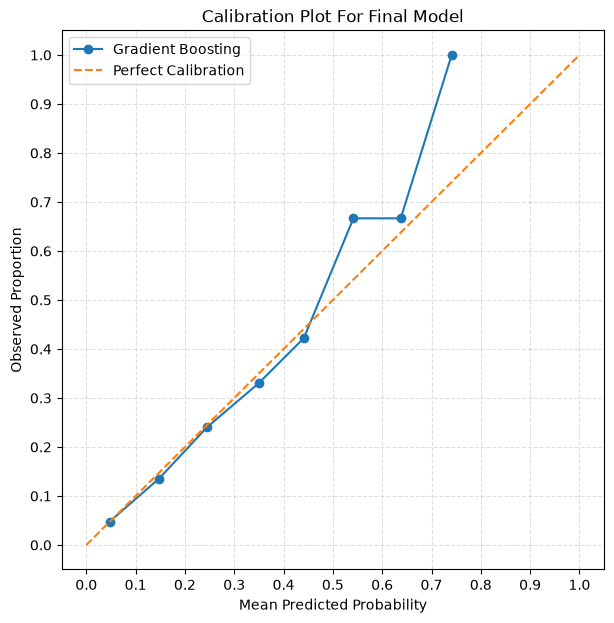

,Observations,Mean_Predicted,Observed_Rate
Probability Bin,,,
"(-0.001, 0.1]",462,0.047,0.048
"(0.1, 0.2]",236,0.148,0.136
"(0.2, 0.3]",187,0.245,0.241
"(0.3, 0.4]",106,0.350,0.33
"(0.4, 0.5]",45,0.441,0.422
"(0.5, 0.6]",15,0.542,0.667
"(0.6, 0.7]",9,0.638,0.667
"(0.7, 0.8]",4,0.741,1.0
"(0.8, 0.9]",0,NaN,<NA>


In [273]:
from sklearn.calibration import calibration_curve

#Calculate calibration curve values.
prob_true, prob_pred = calibration_curve(
    y_test,
    y_test_prob,
    n_bins=10)

#Create calibration plot.
plt.figure(figsize=(7, 7))

#Plot Gradient Boosting calibration curve.
plt.plot(
    prob_pred,
    prob_true,
    marker='o',
    label='Gradient Boosting')

#Plot perfect calibration line.
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Perfect Calibration')

#Add ticks for every 10% rather than every 20%.
ticks = np.arange(0, 1.1, 0.1)

plt.xticks(ticks)
plt.yticks(ticks)

#Add grid lines.
plt.grid(
    True,
    linestyle='--',
    alpha=0.4)

plt.xlabel('Mean Predicted Probability')
plt.ylabel('Observed Proportion')
plt.title('Calibration Plot For Final Model')
plt.legend()
plt.show()

print('\n')

#Create a dataframe containing the predicted probabilities and actual outcomes.
calibration_data = pd.DataFrame({
    'Predicted Probability': y_test_prob,
    'Actual': y_test })

#Create probability bins from 0.0 to 1.0 in 10% increments.
bins = np.arange(0, 1.1, 0.1)

#Assign each observation to a probability bin.
calibration_data['Probability Bin'] = pd.cut(
    calibration_data['Predicted Probability'],
    bins=bins,
    include_lowest=True)

#Group observations by predicted probability bin.
calibration_table = calibration_data.groupby(
    'Probability Bin', observed=False).agg(
    Observations=('Predicted Probability', 'count'),
    Mean_Predicted=('Predicted Probability', 'mean'),
    Observed_Rate=('Actual', 'mean') )

#Display the calibration table rounded to three decimals.
display(calibration_table.round(3))

## Calibration Analysis

Calibration analysis indicates that the model is well calibrated for the vast majority of test observations. Most predictions fell below a predicted probability of 50%, and within these probability ranges, the predicted and observed diabetes rates were generally very similar, often within 2 percentage points of each other.

Deviations became more pronounced at higher predicted probabilities. However, these ranges contained very few observations. Only 15 observations fell between 50–60%, 9 between 60–70%, and 4 between 70–80%, while no observations received predicted probabilities above 80%. Therefore, the apparent poor calibration at the highest probabilities should be interpreted cautiously because these estimates are based on very limited observations and are consequently less reliable.

## Conclusion:

Overall, the model demonstrated reasonably good calibration on the test set. The predicted probability was within 2 percentage points of the observed probability for 97.4% of observations and within 1.2 percentage points for 83.2% of observations. For 98.2% of observations, the predicted probability was within 2.9 percentage points of the observed probability.

These results suggest that the model's probability estimates are reasonably well aligned with observed diabetes rates for the large majority of participants. The apparent deviations at the highest predicted probabilities should not be interpreted as strong evidence of poor model calibration because very few test observations received probabilities in those ranges.

## Model Experimentation

To gain a better understanding of how the final model responds to different risk profiles, predictions will be generated for a series of fictitious individuals. By holding most variables constant while systematically changing one or two features at a time, I can examine how individual characteristics affect the model's predicted probability of diabetes. The examples will include an extremely low-risk profile, an extremely high-risk profile, and several individuals with combinations of multiple risk factors. This approach will help illustrate how the model combines different characteristics when generating individualized predictions and may provide insight into potential interactions between features.

In [314]:
#Create a DataFrame where various predictor values are changed from a baseline set of values.
test_ppl = pd.DataFrame({ 
    'SEQN': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 
             19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35],
    
    'age': [45, 45, 45, 45, 45, 55, 65, 85, 25, 18, 45, 45, 45, 45, 45, 45, 
            45, 45, 45, 45, 45, 45, 45, 45, 45, 65, 45, 45, 45, 18, 80, 45, 65, 25, 
            25],
    
    'sex': ['M','F','M','M','M','M','M','M','M','M','M','M', 'M','M','M','M',
            'M','M','M','M','M','M', 'M','M','M','F','M','M','M','F','M','M', 
            'F', 'M', 'M'],
    
    'race': ['White','White','Asian','Hispanic','Black','White', 'White',
            'White','White','White','White','White','White', 'White',
            'White','White','White','White','White','White','White',
            'White','White','White','White','Asian','White','White', 
             'White','White','Black','Hispanic', 'Asian', 'White', 'Asian'],
    
    'income_ratio': [2.5, 2.5, 2.5, 2.5, 2.5, 2.5, 2.5, 2.5, 2.5, 2.5, 0.5, 
                     3.5, 4.5, 6.5, 2.5, 2.5, 2.5, 2.5, 2.5, 2.5, 2.5, 2.5, 
                     2.5, 2.5, 2.5, 1.0, 2.5, 2.5, 2.5, 5.0, 0.5, 1.5, 1.0, 
                     1.0, 1.0],
    
    'bmi': [24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 24, 20, 28,
            32, 36, 24, 24, 24, 24, 24, 24, 24, 40, 24, 24, 24, 20, 45, 30, 
            40, 40, 40],
    
    'smoked_100': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 
                   1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1],
    
    'drank_heavily': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 
                      1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1],
    
    'weekly_exercise': [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 
                        2, 2, 2, 0, 4, 7, 14, 14, 2, 2, 2, 14, 0, 1, 0, 0, 0],
    
    'sedentary_mins': [300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 
                       300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 300, 
                       300, 300, 300, 0, 0, 500, 700, 0, 900, 300, 800, 900,
                       900] })

In [315]:
#Transform the test data using the full pipeline.
test_transformed = full_pipeline.transform(test_ppl)

#Obtain predictions for the fictitious respondents.
predictions = final_model.predict_proba(test_transformed)[:, 1]

#Create a column showing the predictions.
test_ppl['Predict'] = predictions.round(3)*100

#Display the dataframe with predictions
display(test_ppl)

,SEQN,age,sex,race,income_ratio,bmi,smoked_100,drank_heavily,weekly_exercise,sedentary_mins,Predict
0,1,45,M,White,2.5,24,0,0,2,300,5.5
1,2,45,F,White,2.5,24,0,0,2,300,4.6
2,3,45,M,Asian,2.5,24,0,0,2,300,7.7
3,4,45,M,Hispanic,2.5,24,0,0,2,300,7.7
4,5,45,M,Black,2.5,24,0,0,2,300,7.7
5,6,55,M,White,2.5,24,0,0,2,300,10.3
6,7,65,M,White,2.5,24,0,0,2,300,14.0
7,8,85,M,White,2.5,24,0,0,2,300,16.4
8,9,25,M,White,2.5,24,0,0,2,300,2.1
9,10,18,M,White,2.5,24,0,0,2,300,2.1


## Test Summary

The final Gradient Boosting model was tested using a series of hypothetical individuals which hold most characteristics constant while varying individual risk factors. The results provided insight into how the model combines demographic, behavioral, and health-related characteristics when generating individualized diabetes risk estimates.

Age and BMI produced some of the largest changes in predicted probability. For example, increasing age from 45 to 65 while holding the other characteristics constant increased the predicted probability from approximately 5.5% to 14.0%. Similarly, increasing BMI from 24 to 36 increased the predicted probability from approximately 5.5% to 15.3%. Changes to individual demographic and behavioral characteristics generally produced smaller changes when considered in isolation.

The examples involving multiple risk factors produced more substantial changes in predicted probability. A 45-year-old Hispanic individual with a BMI of 30, a history of smoking, low income, and limited exercise received a predicted probability of 22.4%. A 65-year-old Asian individual with a BMI of 40, smoking history, low income, no weekly exercise, and 800 sedentary minutes per day received a predicted probability of 54.9%. An 80-year-old individual with a BMI of 45 and multiple additional risk factors received a predicted probability of 80.6%.

An especially interesting comparison was between two 25-year-old individuals with nearly identical high-risk characteristics but different racial categories. Their predicted probabilities were 13.3% and 18.2%, respectively. Despite having severe combinations of risk factors, their predicted probabilities remained substantially lower than those of older individuals with similar risk profiles. This suggests that age has a particularly strong influence on the model's predictions and that the combination of multiple risk factors does not necessarily overcome the effect of younger age.

An additional comparison demonstrated the potential importance of physical activity. Two otherwise identical 65-year-old individuals had the same BMI, income, race, smoking history, and alcohol consumption. The first individual exercised 14 times per week and had no sedentary time recorded, while the second did not exercise and reported 800 sedentary minutes per day. Their predicted probabilities were 34.7% and 54.9%, respectively, a difference of more than 20 percentage points. This suggests that physical activity and sedentary behavior may have a moderating effect, reducing the impact of other risk factors.

Overall, these experiments demonstrate that the model does not rely on a single risk factor, but combines multiple characteristics when generating individualized predictions. Age and BMI appeared particularly influential, while the comparison of otherwise identical individuals also demonstrates that increased physical activity appears to be associated with lower risk.

## Create a Deployment Pipeline
 When deploying a model it is important to exclude any code that will not be needed during deployment and use of the model. A lighter pipeline is created which excludes the custom imputer. When being used, the model will never encounter missing values so this functionality can be safely eliminated. To preserve the transformations expected by the trained model, a clean copy of the training data is first created with income values already imputed.This data is then used to fit the new deployment preprocessing pipeline. Then the full deployment pipeline can be created.

In [348]:
from sklearn.pipeline import Pipeline

#Extract the fitted IncomeImputer.
fitted_income_imputer = (
    full_pipeline
    .named_steps['columntransformer']
    .named_transformers_['num']
    .named_steps['incomeimputer'] )


#Create a clean copy of the training data.
X_train_clean = x_train.copy()

#create a copy of training data with the income values imputed.
X_train_imputed = fitted_income_imputer.transform(
    x_train[income_imputer_columns])

#Replace income_ratio values in clean copy with the imputed values. 
X_train_clean['income_ratio'] = X_train_imputed['income_ratio']

#Create a simplified preprocessing pipeline for deployment.
deployment_preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(), numeric_columns),
    ('categorical', OneHotEncoder(drop='first'), categorical_columns),
    ('binary', 'passthrough', binary_columns) ])

#Fit the new deployment preprocessor to the cleaned training data.
deployment_preprocessor.fit(X_train_clean)

#Create a deployment pipeline by combining the fitted pre-processor & final model.
deployment_pipeline = Pipeline([
    ('preprocessor', deployment_preprocessor),
    ('model', final_model) ])

### Create a Function to Deploy the Model
A function is created to pass a DataFrame through the deployment pipeline and return it with a column providing the predicted probability of diabetes.

In [349]:
def predict_diabetes(data):
    predictions = deployment_pipeline.predict_proba(data)[:, 1] * 100
    
    result = data.copy()
    result['Prediction'] = predictions.round(1)
    
    return result

### Test the Deployment Predictions
The simplified deployment pipeline is tested using the same hypothetical individuals used previously. Predictions from the deployment pipeline are compared directly with the original model predictions. The new predictions should be identical or extremely similar to the previous ones.

In [350]:
#Create new identical test_ppl dataframe
test_ppl2 = test_ppl.drop(columns='Predict').copy()

#Create predictions using the deployment function.
deploy_predictions = predict_diabetes(test_ppl2)

#Create a dataframe comparing the original and deployment predictions.
#Step 1: Copy test_ppl containing predictions
comparison = test_ppl.copy()

#Step 2 Create a new column with the new predictions
comparison['Predict2'] = deploy_predictions['Prediction']

#Step 3 Subtract 1st and 2nd predictions in a new column
comparison['Diff'] = (
    comparison['Predict'] - comparison['Predict2']).round(2)

#Display the comparison dataframe
display(comparison)

,SEQN,age,sex,race,income_ratio,bmi,smoked_100,drank_heavily,weekly_exercise,sedentary_mins,Predict,Predict2,Diff
0,1,45,M,White,2.5,24,0,0,2,300,5.5,5.5,0.0
1,2,45,F,White,2.5,24,0,0,2,300,4.6,4.6,0.0
2,3,45,M,Asian,2.5,24,0,0,2,300,7.7,7.7,0.0
3,4,45,M,Hispanic,2.5,24,0,0,2,300,7.7,7.7,0.0
4,5,45,M,Black,2.5,24,0,0,2,300,7.7,7.7,0.0
5,6,55,M,White,2.5,24,0,0,2,300,10.3,10.3,-0.0
6,7,65,M,White,2.5,24,0,0,2,300,14.0,14.0,0.0
7,8,85,M,White,2.5,24,0,0,2,300,16.4,16.4,0.0
8,9,25,M,White,2.5,24,0,0,2,300,2.1,2.1,0.0
9,10,18,M,White,2.5,24,0,0,2,300,2.1,2.1,0.0


### Deployment Pipeline Validation
Predictions generated by the simplified deployment pipeline were compared with predictions previously generated using the original preprocessing workflow across 35 hypothetical observations. All predicted probabilities were identical confirming that removal of the custom imputer from the original pipeline did not meaningfully change the model predictions.
## Save the Model for Deployment & Use

In [351]:
import joblib

#Save the deployment preprocessing pipeline accompanied with the final model.
joblib.dump(deployment_pipeline, 'diabetes_risk_model.joblib')

['diabetes_risk_model.joblib']

## Flask Application Images
After saving the final model and preprocessing pipeline, a Flask application was developed to provide a user-friendly experience. The User enters readily available information such as height, weight, income and household size. The application automatically calculates the feature values needed for bmi and income_ratio passing a complete feature set to the model. The application then displays the model's estimated probability along with a summary of the profile submitted. This creates a seamless, accessible interaction with the model developed.

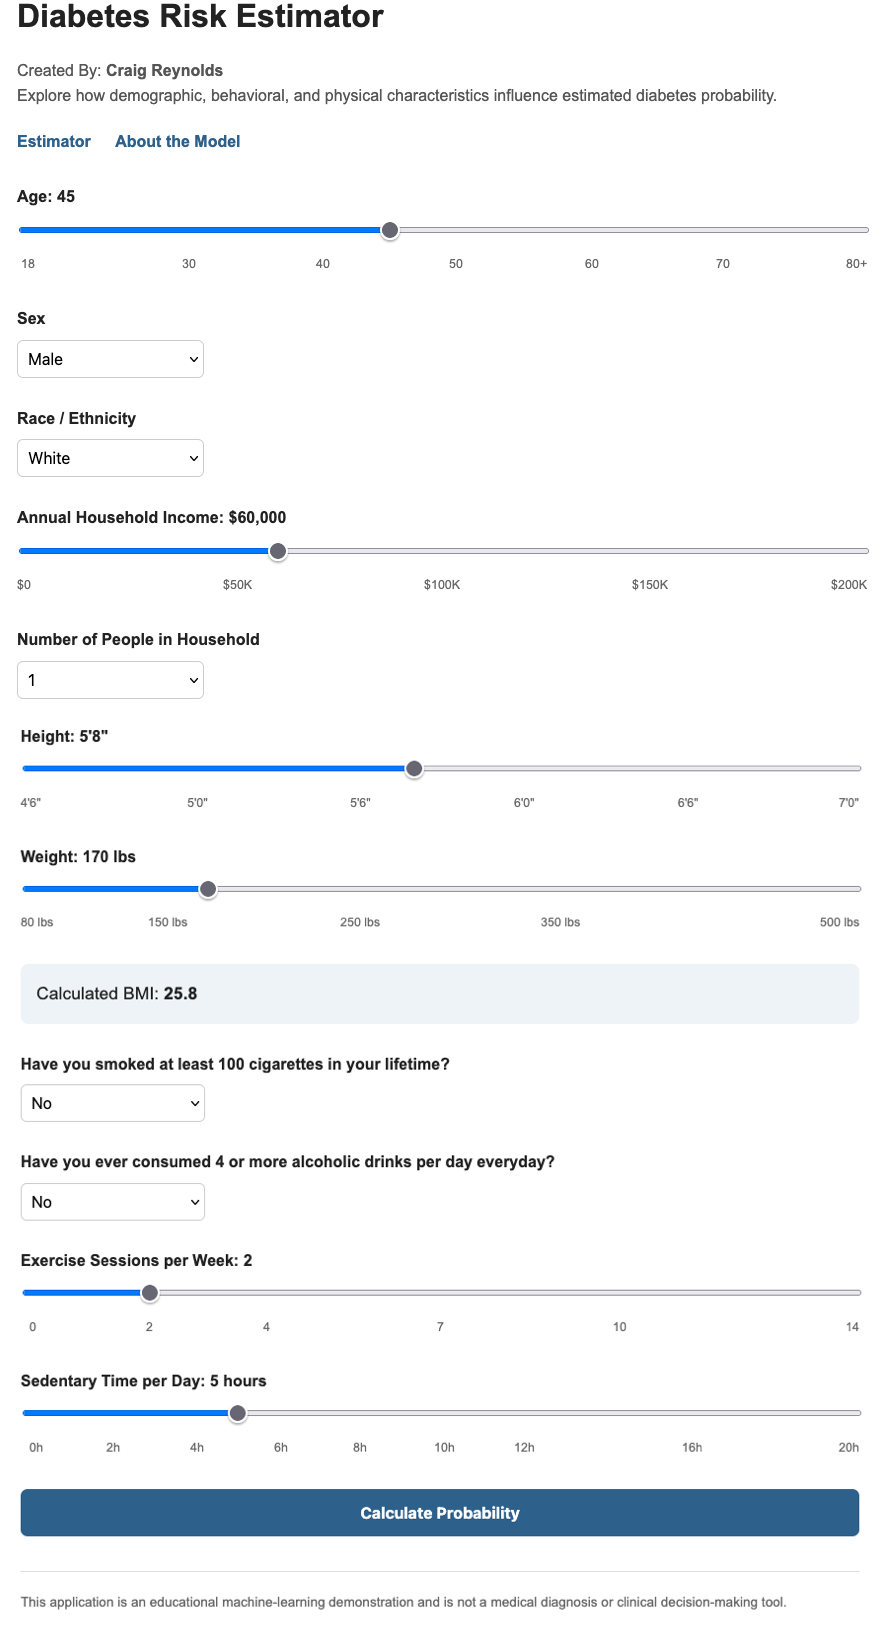

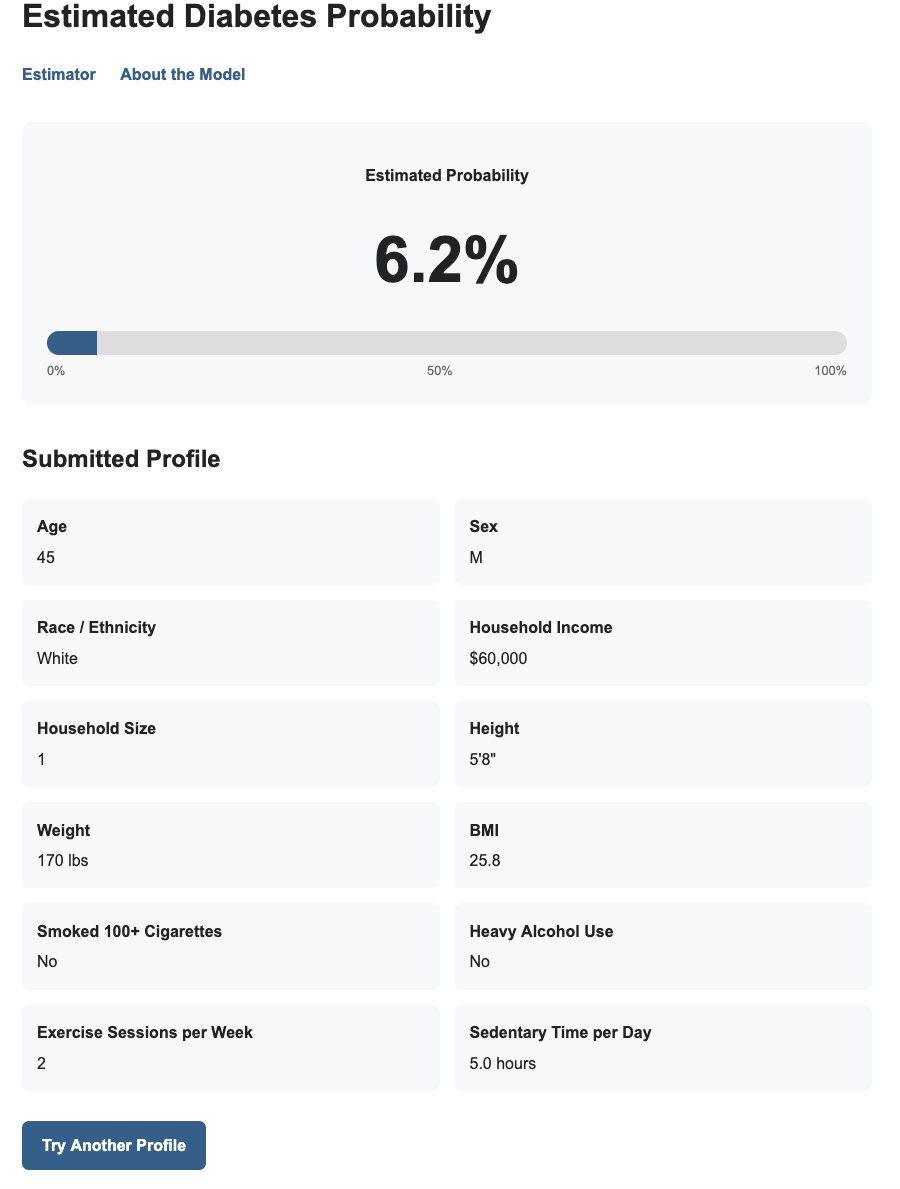

In [359]:
from IPython.display import Image, display

display(Image(filename='images/pic5.png', width=600))
display(Image(filename='images/pic3.png', width=600))